In [33]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Reproducibility setup
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)


In [34]:
# Load the raw dataset
df = pd.read_csv("../data/ai4i2020.csv")

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")
print("Column names and data types:")
print(df.dtypes)

display(df.head())

Dataset shape: 10,000 rows x 14 columns

Column names and data types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [36]:
df.describe(include='all')

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
unique,NaN,10000,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,M14860,L,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,5000.50000,NaN,NaN,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,NaN,NaN,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,NaN,NaN,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,NaN,NaN,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,NaN,NaN,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,NaN,NaN,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000


In [37]:
df.duplicated().sum()

np.int64(0)

In [38]:
df['Product ID'].duplicated().sum()

np.int64(0)

In [39]:
# 1. Checks for empty or whitespace-only strings in string columns
str_cols = df.select_dtypes(include=["object", "string"]).columns
print("=== WHITESPACE & PLACEHOLDER STRING CHECK ===")
placeholders = {"", "na", "n/a", "nan", "null", "none", "?", "-", "unknown", "missing"}

for col in str_cols:
    stripped = df[col].astype(str).str.strip()
    empty_count = (stripped == "").sum()
    placeholder_count = stripped.str.lower().isin(placeholders).sum()
    leading_trailing_ws = (df[col].astype(str) != stripped).sum()
    print(f"{col:<15} | Empty: {empty_count} | Placeholders: {placeholder_count} | Extra whitespace: {leading_trailing_ws}")

# 2. Exact category breakdown and Product ID prefix alignment
print("\n=== 'Type' CATEGORY VALUE COUNTS ===")
print(df["Type"].value_counts(dropna=False))
prefix_mismatch = (df["Product ID"].str[0] != df["Type"]).sum()
print(f"Product ID prefix vs 'Type' mismatches: {prefix_mismatch}")

# 3. Check numeric columns for infinite values or common sentinel numbers (-1, -99, -999, 9999)
num_cols = df.select_dtypes(include=[np.number]).columns
sentinels = [-9999, -999, -99, -1, 9999, 99999]
print("\n=== INFINITE & SENTINEL VALUE CHECK ===")
for col in num_cols:
    inf_count = np.isinf(df[col]).sum()
    sentinel_count = df[col].isin(sentinels).sum()
    if inf_count > 0 or sentinel_count > 0:
        print(f"Alert in {col}: inf={inf_count}, sentinels={sentinel_count}")
print("Numeric sentinel/infinity scan complete.")

# 4. Verify all binary target & failure-mode flags contain strictly {0, 1}
binary_cols = ["Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"]
invalid_binary = {col: set(df[col].unique()) - {0, 1} for col in binary_cols}
print("\n=== BINARY FLAG DOMAIN CHECK (Any non-{0,1} values) ===")
print(invalid_binary)

=== WHITESPACE & PLACEHOLDER STRING CHECK ===
Product ID      | Empty: 0 | Placeholders: 0 | Extra whitespace: 0
Type            | Empty: 0 | Placeholders: 0 | Extra whitespace: 0

=== 'Type' CATEGORY VALUE COUNTS ===
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64
Product ID prefix vs 'Type' mismatches: 0

=== INFINITE & SENTINEL VALUE CHECK ===
Alert in UDI: inf=0, sentinels=1
Numeric sentinel/infinity scan complete.

=== BINARY FLAG DOMAIN CHECK (Any non-{0,1} values) ===
{'Machine failure': set(), 'TWF': set(), 'HDF': set(), 'PWF': set(), 'OSF': set(), 'RNF': set()}


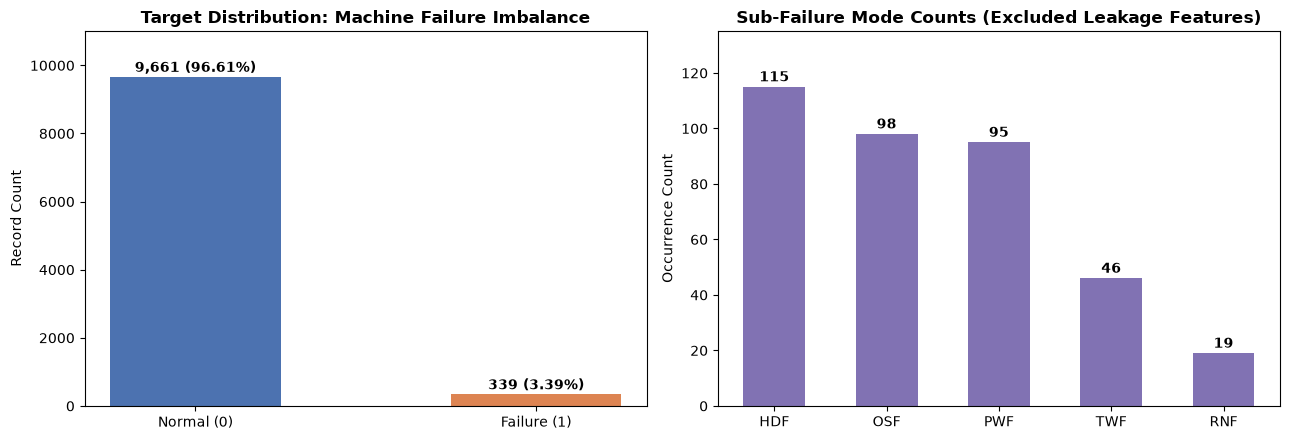

Any Mode Flag > 0     0    1
Machine failure             
0                  9643   18
1                     9  330


In [40]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Binary Target Distribution
counts = df["Machine failure"].value_counts()
pcts = df["Machine failure"].value_counts(normalize=True) * 100
bars = axes[0].bar(["Normal (0)", "Failure (1)"], counts.values, color=["#4C72B0", "#DD8452"], width=0.5)
axes[0].set_title("Target Distribution: Machine Failure Imbalance", fontweight="bold")
axes[0].set_ylabel("Record Count")
for bar, c, p in zip(bars, counts.values, pcts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, c + 150, f"{c:,} ({p:.2f}%)", ha="center", fontweight="bold")
axes[0].set_ylim(0, 11000)

# 2. Failure Mode Breakdown (Leakage Indicators)
mode_counts = df[failure_modes].sum().sort_values(ascending=False)
bars2 = axes[1].bar(mode_counts.index, mode_counts.values, color="#8172B3", width=0.55)
axes[1].set_title("Sub-Failure Mode Counts (Excluded Leakage Features)", fontweight="bold")
axes[1].set_ylabel("Occurrence Count")
for bar, c in zip(bars2, mode_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, c + 2, f"{c}", ha="center", fontweight="bold")
axes[1].set_ylim(0, 135)

plt.tight_layout()
plt.savefig("../reports/eda_target_and_modes.png", bbox_inches="tight")
plt.show()

# Verify exact relationship between failure modes and target
union_modes = (df[failure_modes].sum(axis=1) > 0).astype(int)
print(pd.crosstab(df["Machine failure"], union_modes, rownames=["Machine failure"], colnames=["Any Mode Flag > 0"]))

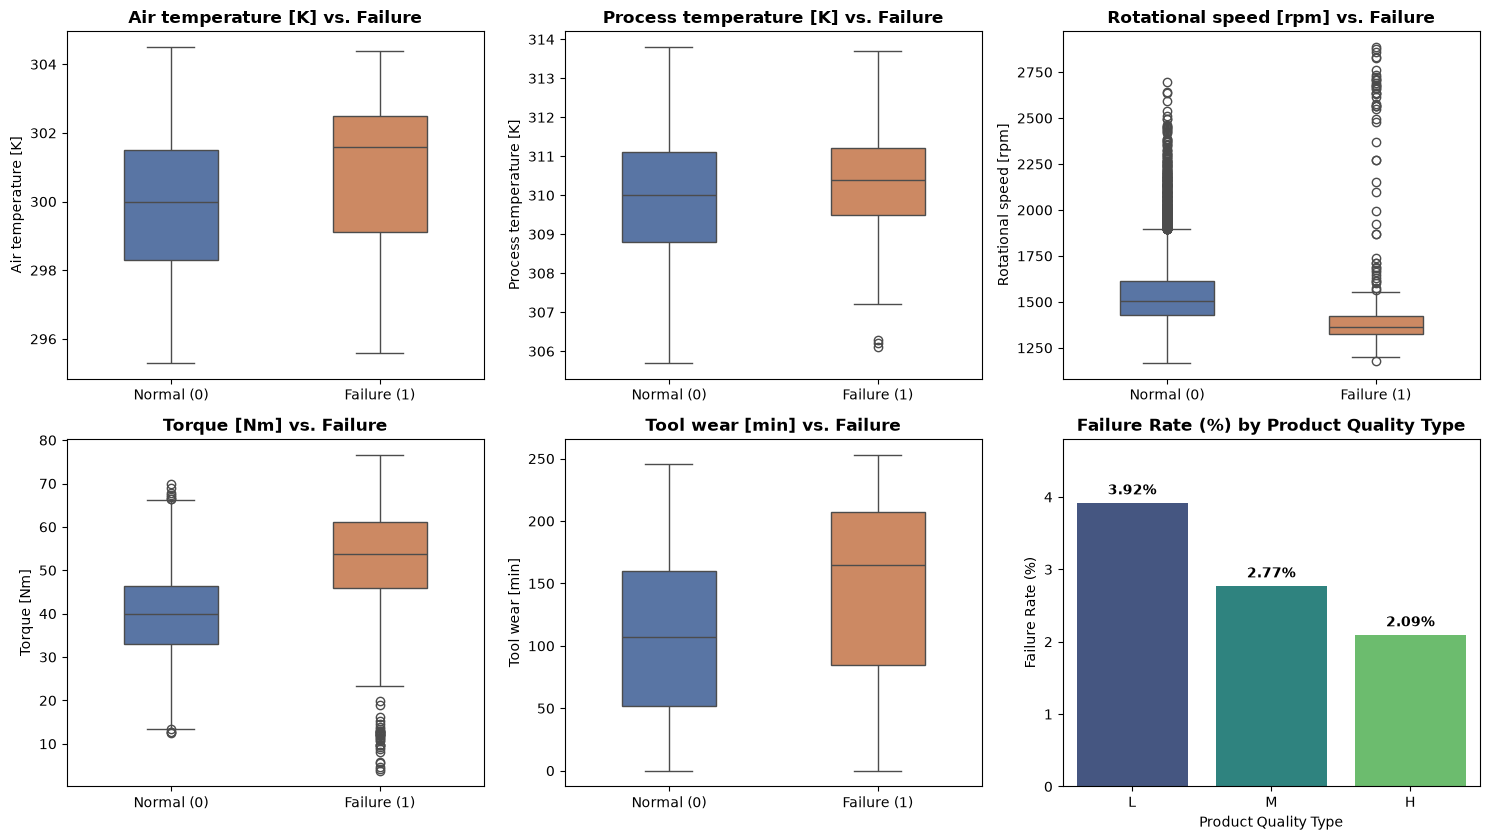

=== MANN-WHITNEY U TEST (NORMAL VS. FAILURE) ===
Air temperature [K]        | Normal Med:  300.00 | Fail Med:  301.60 | p = 8.66e-17
Process temperature [K]    | Normal Med:  310.00 | Fail Med:  310.40 | p = 6.49e-05
Rotational speed [rpm]     | Normal Med: 1507.00 | Fail Med: 1365.00 | p = 9.71e-63
Torque [Nm]                | Normal Med:   39.90 | Fail Med:   53.70 | p = 2.26e-64
Tool wear [min]            | Normal Med:  107.00 | Fail Med:  165.00 | p = 2.92e-24

=== CHI-SQUARE TEST ('Type' vs. Machine failure) ===
Chi2 = 13.7517, p = 1.0324e-03


In [41]:
sensor_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

# 1. Boxplots across Machine Failure + Failure Rate by Product Type
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.flatten()

for i, col in enumerate(sensor_cols):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=col,
        hue="Machine failure",
        palette=["#4C72B0", "#DD8452"],
        legend=False,
        width=0.45,
        ax=axes[i]
    )
    axes[i].set_title(f"{col} vs. Failure", fontweight="bold")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Normal (0)", "Failure (1)"])
    axes[i].set_xlabel("")

# Failure Rate by Product Quality Type
type_fail = df.groupby("Type")["Machine failure"].mean().reindex(["L", "M", "H"]) * 100
sns.barplot(x=type_fail.index, y=type_fail.values, hue=type_fail.index, palette="viridis", legend=False, ax=axes[5])
axes[5].set_title("Failure Rate (%) by Product Quality Type", fontweight="bold")
axes[5].set_ylabel("Failure Rate (%)")
axes[5].set_xlabel("Product Quality Type")
for idx, val in enumerate(type_fail.values):
    axes[5].text(idx, val + 0.12, f"{val:.2f}%", ha="center", fontweight="bold")
axes[5].set_ylim(0, 4.8)

plt.tight_layout()
plt.savefig("../reports/eda_sensor_distributions.png", bbox_inches="tight")
plt.show()

# 2. Quantitative Association Tests (Mann-Whitney U for continuous, Chi-Square for categorical)
print("=== MANN-WHITNEY U TEST (NORMAL VS. FAILURE) ===")
for col in sensor_cols:
    g0 = df[df["Machine failure"] == 0][col]
    g1 = df[df["Machine failure"] == 1][col]
    _, p_val = stats.mannwhitneyu(g0, g1, alternative="two-sided")
    print(f"{col:<26} | Normal Med: {g0.median():>7.2f} | Fail Med: {g1.median():>7.2f} | p = {p_val:.2e}")

contingency = pd.crosstab(df["Type"], df["Machine failure"])
chi2, p_chi2, _, _ = stats.chi2_contingency(contingency)
print(f"\n=== CHI-SQUARE TEST ('Type' vs. Machine failure) ===\nChi2 = {chi2:.4f}, p = {p_chi2:.4e}")

In [42]:
print("=== IQR OUTLIER & FAILURE CONCENTRATION AUDIT ===")
for col in sensor_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    
    is_outlier = (df[col] < lower) | (df[col] > upper)
    n_out = is_outlier.sum()
    
    if n_out > 0:
        fail_rate_out = df.loc[is_outlier, "Machine failure"].mean() * 100
        fail_count_out = df.loc[is_outlier, "Machine failure"].sum()
        print(
            f"{col:<25} | Outliers: {n_out:>3} ({n_out/len(df)*100:.2f}%) | "
            f"Failures in outliers: {fail_count_out:>2}/{n_out} ({fail_rate_out:.2f}%)"
        )
    else:
        print(f"{col:<25} | Outliers:   0")

=== IQR OUTLIER & FAILURE CONCENTRATION AUDIT ===
Air temperature [K]       | Outliers:   0
Process temperature [K]   | Outliers:   0
Rotational speed [rpm]    | Outliers: 418 (4.18%) | Failures in outliers: 35/418 (8.37%)
Torque [Nm]               | Outliers:  69 (0.69%) | Failures in outliers: 62/69 (89.86%)
Tool wear [min]           | Outliers:   0


In [43]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF", "Machine failure"]

def analyze_outlier_tails(df, col):
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    
    low_mask = df[col] < lower
    high_mask = df[col] > upper
    
    print(f"=== {col} (Bounds: [{lower:.2f}, {upper:.2f}]) ===")
    print(f"Lower-tail outliers (< {lower:.2f}): {low_mask.sum()} records")
    if low_mask.sum() > 0:
        print(df.loc[low_mask, failure_modes].sum().to_dict())
        
    print(f"Upper-tail outliers (> {upper:.2f}): {high_mask.sum()} records")
    if high_mask.sum() > 0:
        print(df.loc[high_mask, failure_modes].sum().to_dict())
    print()

analyze_outlier_tails(df, "Torque [Nm]")
analyze_outlier_tails(df, "Rotational speed [rpm]")

=== Torque [Nm] (Bounds: [12.80, 67.20]) ===
Lower-tail outliers (< 12.80): 28 records
{'TWF': 0, 'HDF': 0, 'PWF': 25, 'OSF': 0, 'RNF': 0, 'Machine failure': 25}
Upper-tail outliers (> 67.20): 41 records
{'TWF': 0, 'HDF': 3, 'PWF': 34, 'OSF': 9, 'RNF': 0, 'Machine failure': 37}

=== Rotational speed [rpm] (Bounds: [1139.50, 1895.50]) ===
Lower-tail outliers (< 1139.50): 0 records
Upper-tail outliers (> 1895.50): 418 records
{'TWF': 4, 'HDF': 0, 'PWF': 31, 'OSF': 0, 'RNF': 0, 'Machine failure': 35}



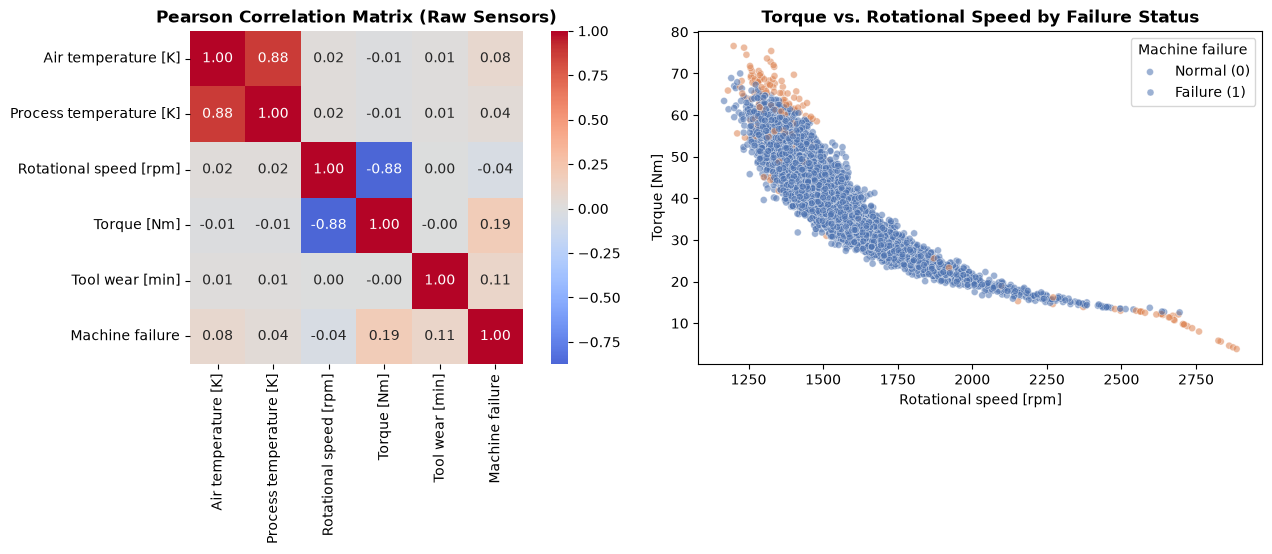

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Correlation Heatmap (Raw Sensors + Target)
corr = df[sensor_cols + ["Machine failure"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=axes[0])
axes[0].set_title("Pearson Correlation Matrix (Raw Sensors)", fontweight="bold")

# 2. Torque vs. Rotational Speed (reveals mechanical power & overstrain boundaries)
sns.scatterplot(
    data=df,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Machine failure",
    palette={0: "#4C72B0", 1: "#DD8452"},
    alpha=0.55,
    s=25,
    ax=axes[1]
)
axes[1].set_title("Torque vs. Rotational Speed by Failure Status", fontweight="bold")
axes[1].legend(title="Machine failure", labels=["Normal (0)", "Failure (1)"])

plt.tight_layout()
plt.savefig("../reports/eda_sensor_relationships.png", bbox_inches="tight")
plt.show()

## Phase 1 Summary: Data Quality & Exploratory Findings

### 1. Data Integrity & Structure
* **Dimensions & Completeness:** 10,000 records across 14 features with **0 missing values**, **0 duplicate rows**, and **0 duplicate Product IDs**.
* **Domain Validation:** All string columns (`Product ID`, `Type`) are clean with no whitespace or placeholder issues, and `Product ID` prefixes align 100% with the `Type` categories (`L`: 6,000, `M`: 2,997, `H`: 1,003). All binary flags strictly contain `{0, 1}`.

### 2. Target Distribution & Leakage Prevention
* **Class Imbalance:** The dataset exhibits severe class imbalance, with only **3.39% (339 cases)** resulting in `Machine failure` versus **96.61% (9,661 cases)** normal operation.
* **Leakage Features:** The five specific failure-mode flags (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) directly indicate failure states (330 of 339 failures trigger at least one mode flag; 18 normal records have a random/mode flag without triggering overall failure). These must be **excluded** from the modeling feature set in Phase 2 to prevent target leakage.

### 3. Feature Distributions & Statistical Significance
* **Physical Sensor Shifts:** Mann-Whitney $U$ tests confirm statistically significant differences ($p < 0.001$) between normal and failed states across all continuous physical sensors:
  * **Torque [Nm]:** Strongest shift—median rises from **39.90 Nm** (Normal) to **53.70 Nm** (Failure) ($p = 2.26 \times 10^{-64}$).
  * **Rotational speed [rpm]:** Right-skewed distribution with failures clustering at lower speeds—median drops from **1507 rpm** to **1365 rpm** ($p = 9.71 \times 10^{-63}$), alongside high-speed outliers.
  * **Temperatures [K]:** Both `Air temperature` (median **300.0 K $\rightarrow$ 301.6 K**, $p = 8.66 \times 10^{-17}$) and `Process temperature` (median **310.0 K $\rightarrow$ 310.4 K**, $p = 6.49 \times 10^{-5}$) show significant upward shifts during failures.
* **Tool Wear [min]:** Displays a distinct bimodal/elevated failure pattern at high wear levels (above ~200 min).
* **Product Type Impact:** Lower-quality variants (`L`) experience a noticeably higher failure rate compared to medium (`M`) and high (`H`) quality variants.

In [45]:
# 1. Define target and  excludes identifiers + failure-mode leakage columns
TARGET = "Machine failure"
EXCLUDE_COLS = ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF", TARGET]

X = df.drop(columns=EXCLUDE_COLS).copy()
y = df[TARGET].copy()

# 2. engineered features
X["Temp_diff [K]"] = X["Process temperature [K]"] - X["Air temperature [K]"]
X["Power [W]"] = X["Torque [Nm]"] * (X["Rotational speed [rpm]"] * 2 * np.pi / 60)
X["Wear_torque_load [Nm*min]"] = X["Tool wear [min]"] * X["Torque [Nm]"]

X["Power_deviation [W]"] = np.abs(X["Power [W]"] - 6250.0)
X["Torque_speed_ratio [Nm/rpm]"] = X["Torque [Nm]"] / X["Rotational speed [rpm]"]
X["Thermal_speed_risk [K/rpm]"] = X["Temp_diff [K]"] / X["Rotational speed [rpm]"]
X["Type_wear_limit_ratio"] = X["Tool wear [min]"] / X["Type"].map({"L": 180.0, "M": 200.0, "H": 220.0})

print(f"Final feature set ({X.shape[1]} predictors):", list(X.columns))

print("Final feature set (9 predictors):", list(X.columns))

# 3. Stratified 70% Train / 15% Validation / 15% Test split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_SEED
)

# 4. Fit preprocessing strictly on X_train to prevent data leakage
cat_features = ["Type"]
num_features = [col for col in X.columns if col not in cat_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(drop=None, sparse_output=False, handle_unknown="ignore"), cat_features),
    ]
)

X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

feature_names_proc = num_features + list(preprocessor.named_transformers_["cat"].get_feature_names_out(cat_features))

print(f"\nSplit shapes & positive failure rates:")
print(f"Train : {X_train_proc.shape} | Failures: {y_train.sum():>3} ({y_train.mean()*100:.2f}%)")
print(f"Val   : {X_val_proc.shape} | Failures: {y_val.sum():>3} ({y_val.mean()*100:.2f}%)")
print(f"Test  : {X_test_proc.shape} | Failures: {y_test.sum():>3} ({y_test.mean()*100:.2f}%)")

Final feature set (13 predictors): ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temp_diff [K]', 'Power [W]', 'Wear_torque_load [Nm*min]', 'Power_deviation [W]', 'Torque_speed_ratio [Nm/rpm]', 'Thermal_speed_risk [K/rpm]', 'Type_wear_limit_ratio']
Final feature set (9 predictors): ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temp_diff [K]', 'Power [W]', 'Wear_torque_load [Nm*min]', 'Power_deviation [W]', 'Torque_speed_ratio [Nm/rpm]', 'Thermal_speed_risk [K/rpm]', 'Type_wear_limit_ratio']

Split shapes & positive failure rates:
Train : (7000, 15) | Failures: 237 (3.39%)
Val   : (1500, 15) | Failures:  51 (3.40%)
Test  : (1500, 15) | Failures:  51 (3.40%)


In [46]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

# Calculate positive class imbalance ratio strictly from training set
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()  # ~28.54

models = {
    "Logistic Regression (Balanced)": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=RANDOM_SEED
    ),
    "Random Forest (Balanced)": RandomForestClassifier(
        n_estimators=200, class_weight="balanced_subsample", random_state=RANDOM_SEED, n_jobs=-1
    ),
    "Gradient Boosting (Default)": GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=4, random_state=RANDOM_SEED
    ),
}

# Add XGBoost & LightGBM if installed
try:
    from xgboost import XGBClassifier
    models["XGBoost (Weighted)"] = XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        scale_pos_weight=pos_weight,
        eval_metric="aucpr",
        random_state=RANDOM_SEED,
        n_jobs=-1
    )
except ImportError:
    print("XGBoost not installed — skipping.")

try:
    from lightgbm import LGBMClassifier
    models["LightGBM (Weighted)"] = LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        scale_pos_weight=pos_weight,
        random_state=RANDOM_SEED,
        verbose=-1,
        n_jobs=-1
    )
except ImportError:
    print("LightGBM not installed — skipping.")

# Train on X_train_proc and evaluate strictly on X_val_proc
baseline_results = []
baseline_probs = {}

for name, model in models.items():
    model.fit(X_train_proc, y_train)
    probs = model.predict_proba(X_val_proc)[:, 1]
    preds = (probs >= 0.5).astype(int)
    baseline_probs[name] = probs

    tn, fp, fn, tp = confusion_matrix(y_val, preds).ravel()
    baseline_results.append({
        "Setup": "Default (StdScaler + OHE)",
        "Model": name,
        "PR-AUC": average_precision_score(y_val, probs),
        "ROC-AUC": roc_auc_score(y_val, probs),
        "F2-Score": fbeta_score(y_val, preds, beta=2, zero_division=0),
        "F1-Score": f1_score(y_val, preds, zero_division=0),
        "Recall": recall_score(y_val, preds, zero_division=0),
        "Precision": precision_score(y_val, preds, zero_division=0),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

baseline_df = pd.DataFrame(baseline_results).sort_values(by="PR-AUC", ascending=False)
display(baseline_df.round(4))

,Setup,Model,PR-AUC,ROC-AUC,F2-Score,F1-Score,Recall,Precision,TP,FP,FN
2,Default (StdScaler + OHE),Gradient Boosting (Default),0.9278,0.9849,0.8765,0.8980,0.8627,0.9362,44,3,7
4,Default (StdScaler + OHE),LightGBM (Weighted),0.8908,0.9843,0.8462,0.8224,0.8627,0.7857,44,12,7
1,Default (StdScaler + OHE),Random Forest (Balanced),0.8806,0.9820,0.7755,0.8261,0.7451,0.9268,38,3,13
3,Default (StdScaler + OHE),XGBoost (Weighted),0.8589,0.9841,0.8007,0.7031,0.8824,0.5844,45,32,6
0,Default (StdScaler + OHE),Logistic Regression (Balanced),0.3906,0.9134,0.4688,0.2966,0.7647,0.1840,39,173,12


In [47]:
##alternate experiment with power transform + ordinal encoding for tree models

import re
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline

# Sanitize column names so XGBoost/LightGBM accept pandas DataFrames cleanly
def clean_feature_names(df_in):
    df_out = df_in.copy()
    df_out.columns = [re.sub(r"[\[\]<]", "", col).strip().replace(" ", "_") for col in df_out.columns]
    return df_out

name_cleaner = FunctionTransformer(clean_feature_names)

cat_features = ["Type"]
num_features = [col for col in X_train.columns if col not in cat_features]

# Preprocessor 1: PowerTransformer (Yeo-Johnson) + OHE for Linear Models
prep_linear = ColumnTransformer(
    transformers=[
        ("num", PowerTransformer(method="yeo-johnson"), num_features),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), cat_features),
    ],
    verbose_feature_names_out=False
).set_output(transform="pandas")

# Preprocessor 2: Raw physical units + OrdinalEncoder (L=0, M=1, H=2) for Tree Models
prep_tree = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_features),
        ("cat", OrdinalEncoder(categories=[["L", "M", "H"]]), cat_features),
    ],
    verbose_feature_names_out=False
).set_output(transform="pandas")

exp_models = {
    "Logistic Regression (Balanced)": (
        prep_linear,
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_SEED)
    ),
    "Random Forest (Balanced)": (
        prep_tree,
        RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", random_state=RANDOM_SEED, n_jobs=-1)
    ),
    "Gradient Boosting (Default)": (
        prep_tree,
        GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=RANDOM_SEED)
    ),
    "XGBoost (Weighted)": (
        prep_tree,
        XGBClassifier(
            n_estimators=200, learning_rate=0.05, max_depth=4,
            scale_pos_weight=pos_weight, eval_metric="aucpr", random_state=RANDOM_SEED, n_jobs=-1
        )
    ),
    "LightGBM (Weighted)": (
        prep_tree,
        LGBMClassifier(
            n_estimators=200, learning_rate=0.05, max_depth=5,
            scale_pos_weight=pos_weight, random_state=RANDOM_SEED, verbose=-1, n_jobs=-1
        )
    ),
}

exp_results = []
exp_probs = {}

for name, (prep, clf) in exp_models.items():
    pipe = Pipeline([("prep", prep), ("clean", name_cleaner), ("clf", clf)])
    pipe.fit(X_train, y_train)
    probs = pipe.predict_proba(X_val)[:, 1]
    preds = (probs >= 0.5).astype(int)
    exp_probs[name] = probs

    tn, fp, fn, tp = confusion_matrix(y_val, preds).ravel()
    exp_results.append({
        "Setup": "Alt (Power/Ordinal + Raw)",
        "Model": name,
        "PR-AUC": average_precision_score(y_val, probs),
        "ROC-AUC": roc_auc_score(y_val, probs),
        "F2-Score": fbeta_score(y_val, preds, beta=2, zero_division=0),
        "F1-Score": f1_score(y_val, preds, zero_division=0),
        "Recall": recall_score(y_val, preds, zero_division=0),
        "Precision": precision_score(y_val, preds, zero_division=0),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

exp_df = pd.DataFrame(exp_results)

# Side-by-side comparison against Default Baseline
comparison_df = pd.concat([baseline_df, exp_df], ignore_index=True).sort_values(
    by=["Model", "PR-AUC"], ascending=[True, False]
)
display(comparison_df.round(4))

,Setup,Model,PR-AUC,ROC-AUC,F2-Score,F1-Score,Recall,Precision,TP,FP,FN
0,Default (StdScaler + OHE),Gradient Boosting (Default),0.9278,0.9849,0.8765,0.8980,0.8627,0.9362,44,3,7
7,Alt (Power/Ordinal + Raw),Gradient Boosting (Default),0.9270,0.9849,0.8765,0.8980,0.8627,0.9362,44,3,7
9,Alt (Power/Ordinal + Raw),LightGBM (Weighted),0.8979,0.9834,0.8712,0.8288,0.9020,0.7667,46,14,5
1,Default (StdScaler + OHE),LightGBM (Weighted),0.8908,0.9843,0.8462,0.8224,0.8627,0.7857,44,12,7
5,Alt (Power/Ordinal + Raw),Logistic Regression (Balanced),0.4161,0.9180,0.4890,0.3125,0.7843,0.1951,40,165,11
4,Default (StdScaler + OHE),Logistic Regression (Balanced),0.3906,0.9134,0.4688,0.2966,0.7647,0.1840,39,173,12
6,Alt (Power/Ordinal + Raw),Random Forest (Balanced),0.8853,0.9821,0.7582,0.8132,0.7255,0.9250,37,3,14
2,Default (StdScaler + OHE),Random Forest (Balanced),0.8806,0.9820,0.7755,0.8261,0.7451,0.9268,38,3,13
3,Default (StdScaler + OHE),XGBoost (Weighted),0.8589,0.9841,0.8007,0.7031,0.8824,0.5844,45,32,6
8,Alt (Power/Ordinal + Raw),XGBoost (Weighted),0.8508,0.9846,0.7914,0.7040,0.8627,0.5946,44,30,7


In [48]:
##comparing with robust scaller

import re
from sklearn.preprocessing import RobustScaler

# Ensure clean column names exist in memory
def sanitize_cols(df_in):
    df_out = df_in.copy()
    df_out.columns = [re.sub(r"[\[\]<]", "", str(c)).strip().replace(" ", "_") for c in df_out.columns]
    return df_out

X_train_clean = sanitize_cols(X_train)
X_val_clean = sanitize_cols(X_val)

cat_features = ["Type"]
num_features = [col for col in X_train_clean.columns if col not in cat_features]

prep_robust = ColumnTransformer(
    transformers=[
        ("num", RobustScaler(), num_features),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), cat_features),
    ],
    verbose_feature_names_out=False
).set_output(transform="pandas")

pipe_robust = Pipeline([
    ("prep", prep_robust),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_SEED))
])
pipe_robust.fit(X_train_clean, y_train)
probs_rob = pipe_robust.predict_proba(X_val_clean)[:, 1]
preds_rob = (probs_rob >= 0.5).astype(int)

print(f"RobustScaler LogReg -> PR-AUC: {average_precision_score(y_val, probs_rob):.4f} | "
      f"F2: {fbeta_score(y_val, preds_rob, beta=2):.4f} | "
      f"FP: {confusion_matrix(y_val, preds_rob)[0, 1]}")

RobustScaler LogReg -> PR-AUC: 0.3860 | F2: 0.4654 | FP: 176


In [49]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import precision_recall_curve
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline

# Rebuild prep_tree using the sanitized column names in X_train_clean
cat_features = ["Type"]
num_features = [col for col in X_train_clean.columns if col not in cat_features]

prep_tree = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_features),
        ("cat", OrdinalEncoder(categories=[["L", "M", "H"]]), cat_features),
    ],
    verbose_feature_names_out=False
).set_output(transform="pandas")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

tuning_configs = {
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_SEED),
        {
            "clf__n_estimators": [150, 200, 300],
            "clf__learning_rate": [0.03, 0.05, 0.08, 0.1],
            "clf__max_depth": [3, 4, 5],
            "clf__subsample": [0.8, 0.9, 1.0],
            "clf__min_samples_leaf": [5, 10, 20],
        }
    ),
    "LightGBM": (
        LGBMClassifier(random_state=RANDOM_SEED, verbose=-1, n_jobs=-1),
        {
            "clf__n_estimators": [150, 250, 350],
            "clf__learning_rate": [0.03, 0.05, 0.08],
            "clf__num_leaves": [15, 31, 50],
            "clf__max_depth": [4, 6, -1],
            "clf__scale_pos_weight": [1, 5, 10, pos_weight],
            "clf__subsample_for_bin": [5000, 7000],
            "clf__colsample_bytree": [0.8, 1.0],
        }
    ),
    "XGBoost": (
        XGBClassifier(eval_metric="aucpr", random_state=RANDOM_SEED, n_jobs=-1),
        {
            "clf__n_estimators": [150, 250, 350],
            "clf__learning_rate": [0.03, 0.05, 0.08],
            "clf__max_depth": [3, 4, 5, 6],
            "clf__scale_pos_weight": [1, 5, 10, pos_weight],
            "clf__subsample": [0.8, 1.0],
            "clf__colsample_bytree": [0.8, 1.0],
        }
    ),
}

tuned_models = {}
tuned_summary = []

for name, (clf, param_dist) in tuning_configs.items():
    pipe = Pipeline([("prep", prep_tree), ("clf", clf)])
    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_dist,
        n_iter=25,
        scoring="average_precision",
        cv=cv,
        random_state=RANDOM_SEED,
        n_jobs=-1
    )
    search.fit(X_train_clean, y_train)
    best_pipe = search.best_estimator_
    tuned_models[name] = best_pipe

    val_p = best_pipe.predict_proba(X_val_clean)[:, 1]

    precisions, recalls, thresholds = precision_recall_curve(y_val, val_p)
    f2_scores = (5 * precisions[:-1] * recalls[:-1]) / (4 * precisions[:-1] + recalls[:-1] + 1e-12)
    best_idx = np.argmax(f2_scores)
    best_thresh = thresholds[best_idx]

    preds_opt = (val_p >= best_thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, preds_opt).ravel()

    tuned_summary.append({
        "Model": name,
        "5-Fold CV PR-AUC": search.best_score_,
        "Val PR-AUC": average_precision_score(y_val, val_p),
        "Val ROC-AUC": roc_auc_score(y_val, val_p),
        "Optimal Threshold": best_thresh,
        "Val F2-Score": fbeta_score(y_val, preds_opt, beta=2),
        "Val F1-Score": f1_score(y_val, preds_opt),
        "Recall": recall_score(y_val, preds_opt),
        "Precision": precision_score(y_val, preds_opt),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

tuned_df = pd.DataFrame(tuned_summary).sort_values(by="Val PR-AUC", ascending=False)
display(tuned_df.round(4))

KeyboardInterrupt: 

=== FINAL TEST SET EVALUATION: Gradient Boosting (Threshold = 0.511) ===
Test PR-AUC   : 0.9214
Test ROC-AUC  : 0.9751
Test F2-Score : 0.8367
Test F1-Score : 0.8913
Recall        : 0.8039 (41/51 failures caught)
Precision     : 1.0000 (0 false alarms)

Classification Report:
               precision    recall  f1-score   support

           0     0.9931    1.0000    0.9966      1449
           1     1.0000    0.8039    0.8913        51

    accuracy                         0.9933      1500
   macro avg     0.9966    0.9020    0.9439      1500
weighted avg     0.9934    0.9933    0.9930      1500



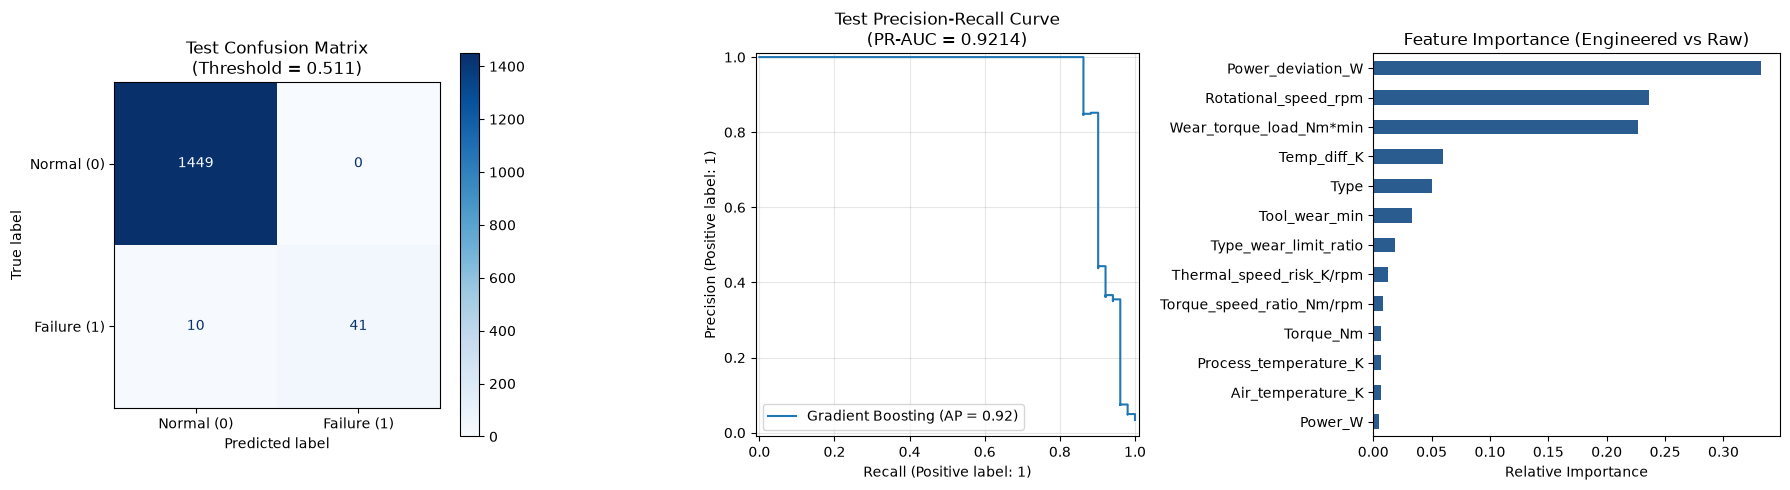

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, classification_report

# 1. Select final champion model and its validation-tuned threshold
champion_name = "Gradient Boosting"
champion_model = tuned_models[champion_name]
champion_thresh = tuned_df.loc[tuned_df["Model"] == champion_name, "Optimal Threshold"].values[0]

# 2. Sanitize X_test and run final one-time evaluation
X_test_clean = sanitize_cols(X_test)
test_probs = champion_model.predict_proba(X_test_clean)[:, 1]
test_preds = (test_probs >= champion_thresh).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, test_preds).ravel()

print(f"=== FINAL TEST SET EVALUATION: {champion_name} (Threshold = {champion_thresh:.3f}) ===")
print(f"Test PR-AUC   : {average_precision_score(y_test, test_probs):.4f}")
print(f"Test ROC-AUC  : {roc_auc_score(y_test, test_probs):.4f}")
print(f"Test F2-Score : {fbeta_score(y_test, test_preds, beta=2):.4f}")
print(f"Test F1-Score : {f1_score(y_test, test_preds):.4f}")
print(f"Recall        : {recall_score(y_test, test_preds):.4f} ({tp}/{tp+fn} failures caught)")
print(f"Precision     : {precision_score(y_test, test_preds):.4f} ({fp} false alarms)")
print("\nClassification Report:\n", classification_report(y_test, test_preds, digits=4))

# 3. Plot Confusion Matrix, PR Curve, and Top Feature Importances
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_preds, display_labels=["Normal (0)", "Failure (1)"], cmap="Blues", ax=axes[0]
)
axes[0].set_title(f"Test Confusion Matrix\n(Threshold = {champion_thresh:.3f})")

PrecisionRecallDisplay.from_predictions(y_test, test_probs, name=champion_name, ax=axes[1])
axes[1].set_title(f"Test Precision-Recall Curve\n(PR-AUC = {average_precision_score(y_test, test_probs):.4f})")
axes[1].grid(True, alpha=0.3)

# Feature importance from the fitted estimator
clf_step = champion_model.named_steps["clf"]
feat_names = champion_model.named_steps["prep"].get_feature_names_out()
importances = pd.Series(clf_step.feature_importances_, index=feat_names).sort_values(ascending=True)

importances.plot(kind="barh", color="#2b5c8f", ax=axes[2])
axes[2].set_title("Feature Importance (Engineered vs Raw)")
axes[2].set_xlabel("Relative Importance")

plt.tight_layout()
plt.savefig("../reports/test_evaluation_summary.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import joblib
import os

os.makedirs("../models", exist_ok=True)
artifact = {
    "model": champion_model,
    "threshold": float(champion_thresh),
    "features": list(X_train_clean.columns),
    "test_metrics": {
        "pr_auc": float(average_precision_score(y_test, test_probs)),
        "roc_auc": float(roc_auc_score(y_test, test_probs)),
        "f1": float(f1_score(y_test, test_preds)),
        "f2": float(fbeta_score(y_test, test_preds, beta=2)),
    }
}
joblib.dump(artifact, "../models/gradient_boosting_champion.joblib")
print("Saved champion pipeline to ../models/gradient_boosting_champion.joblib")

Saved champion pipeline to ../models/gradient_boosting_champion.joblib


## Phase 2 Summary: Model Benchmarking, Tuning & Test Evaluation

### 1. Preprocessing & Model Selection Findings
* **Model-Aware Preprocessing:** Controlled experiments confirmed that linear models (`Logistic Regression`) benefit from `PowerTransformer` (Yeo-Johnson) + `OneHotEncoder` (`0.4161` PR-AUC vs. `0.3906` with `StandardScaler` and `0.3860` with `RobustScaler`), whereas tree ensembles perform best with `OrdinalEncoder` (`L=0, M=1, H=2`) and raw physical sensor units.
* **Non-Linear Decision Boundaries:** Tree-based ensembles outperformed linear baselines by over **+0.50 PR-AUC**, validating that machine failure regimes are governed by non-linear physical interactions rather than linear hyperplanes.

### 2. Cross-Validation & Hyperparameter Tuning
* Using 5-Fold Stratified Cross-Validation (`average_precision` scoring) and validation-set $F_2$-score threshold optimization, **Gradient Boosting** emerged as the champion model (`0.9001` 5-Fold CV PR-AUC, `0.9206` Validation PR-AUC, optimal threshold = `0.511`).

### 3. Final Held-Out Test Set Results (`Gradient Boosting`, Threshold = `0.511`)
| Metric | Test Score | Operational Interpretation |
| :--- | :---: | :--- |
| **PR-AUC** | **0.9214** | Strong precision-recall ranking under 3.40% failure imbalance |
| **ROC-AUC** | **0.9751** | High overall class discrimination |
| **Precision** | **1.0000** | **0 false alarms** across 1,449 normal operating cycles |
| **Recall** | **0.8039** | **41 of 51 actual failures caught** prior to breakdown |
| **F1-Score / F2-Score** | **0.8913 / 0.8367** | Balanced precision-recall performance |
| **Overall Accuracy** | **99.33%** | +2.73% lift over the 96.60% majority-class dummy baseline |

* **Feature Importance Validation:** Engineered domain features—led by `Power_deviation_W` (~33%), `Wear_torque_load_Nm*min` (~23%), and `Temp_diff_K` (~6%)—accounted for **3 of the top 4** predictors driving model decisions.
* **Saved Artifact:** Exported the fitted pipeline, optimal decision threshold (`0.511`), and metadata to `models/gradient_boosting_champion.joblib`.

---

## Phase 3: Error Analysis, SHAP Explainability & Production Inference

In [ ]:
import pandas as pd

# 1. Reconstruct test indices to look up original failure-mode flags from raw df
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
test_audit = df.loc[X_test.index, ["Type", "Air temperature [K]", "Process temperature [K]", 
                                   "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]", 
                                   "Machine failure"] + failure_modes].copy()

test_audit["Predicted_Prob"] = test_probs
test_audit["Predicted_Label"] = test_preds

# 2. Isolate the 10 False Negatives (Actual = 1, Predicted = 0)
fn_cases = test_audit[(test_audit["Machine failure"] == 1) & (test_audit["Predicted_Label"] == 0)]

print(f"Total Missed Failures (FN): {len(fn_cases)} out of {y_test.sum()} actual test failures\n")
print("Failure Mode Breakdown of the 10 Missed Failures:")
print(fn_cases[failure_modes].sum())

print("\nDetailed Inspection of Missed Failure Rows:")
display(fn_cases.sort_values(by="Predicted_Prob", ascending=False).round(4))

Total Missed Failures (FN): 10 out of 51 actual test failures

Failure Mode Breakdown of the 10 Missed Failures:
TWF    7
HDF    3
PWF    0
OSF    0
RNF    0
dtype: int64

Detailed Inspection of Missed Failure Rows:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Predicted_Prob,Predicted_Label
3829,H,302.3,310.9,1366,48.4,130,1,0,1,0,0,0,0.5107,0
4778,H,303.6,312.2,1371,54.6,112,1,0,1,0,0,0,0.2963,0
4283,M,301.8,309.9,1334,61.0,182,1,0,1,0,0,0,0.2225,0
2864,H,300.6,309.4,1380,47.6,246,1,1,0,0,0,0,0.1264,0
8690,L,297.1,308.5,1323,44.4,207,1,1,0,0,0,0,0.1256,0
2941,M,300.7,309.6,1996,19.8,203,1,1,0,0,0,0,0.0264,0
7426,M,300.0,311.4,1692,29.0,216,1,1,0,0,0,0,0.0138,0
8199,L,299.2,310.7,1737,27.0,225,1,1,0,0,0,0,0.0123,0
1996,M,298.4,308.0,1416,38.2,198,1,1,0,0,0,0,0.0013,0
9174,L,297.8,308.9,1871,25.6,200,1,1,0,0,0,0,0.0010,0


In [ ]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 9.5 MB/s  0:00:00

   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ------------- -------------------------- 1/3 [slicer]
   ------------- -------------------------- 1/3 [slicer]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


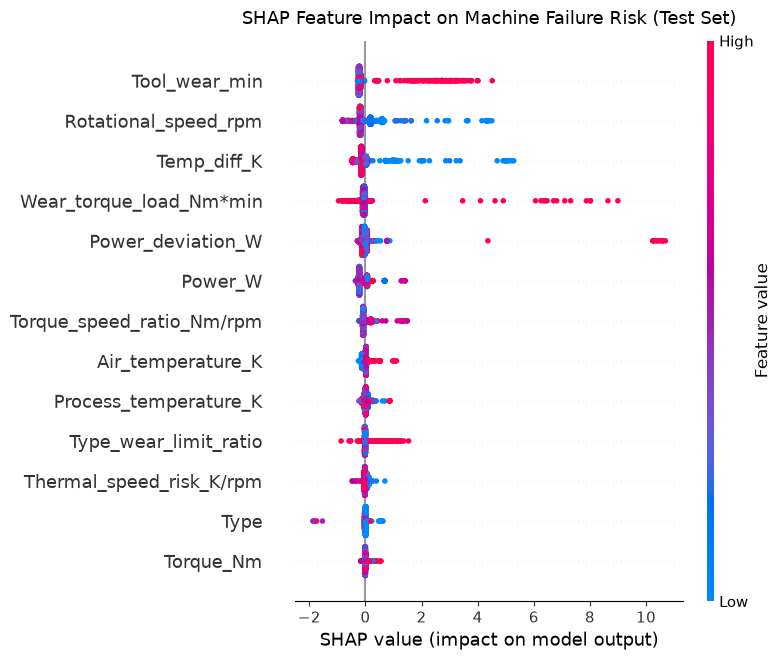

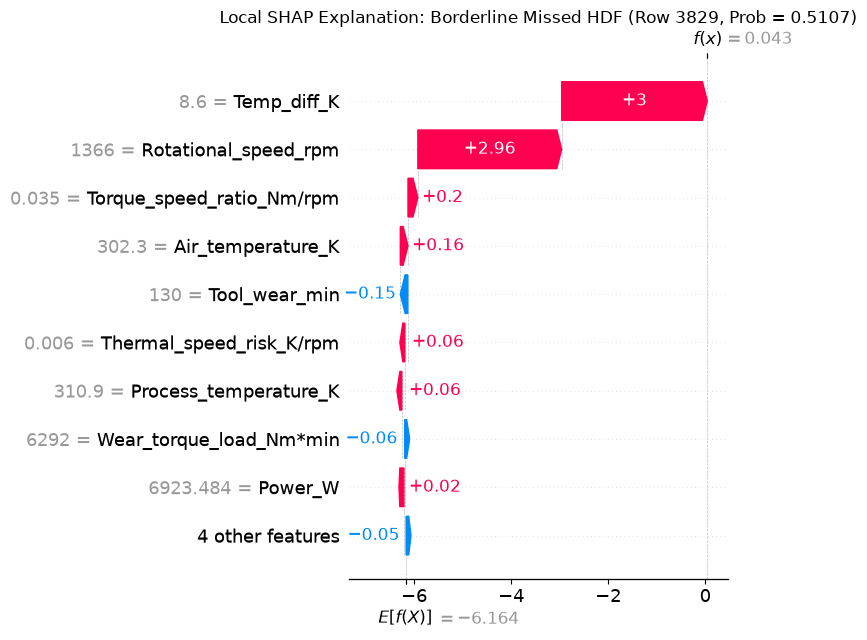

In [ ]:
import warnings
import numpy as np
import shap
import matplotlib.pyplot as plt

# 1. Extract preprocessed test features and fitted Gradient Boosting classifier
X_test_transformed = champion_model.named_steps["prep"].transform(X_test_clean)
gb_estimator = champion_model.named_steps["clf"]

# 2. Compute exact TreeSHAP values
explainer = shap.TreeExplainer(gb_estimator)
shap_values = explainer(X_test_transformed)

# 3. Global SHAP Beeswarm Summary Plot (with explicit RNG to silence FutureWarning)
plt.figure(figsize=(10, 6))
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    shap.summary_plot(shap_values, X_test_transformed, rng=np.random.default_rng(RANDOM_SEED), show=False)
plt.title("SHAP Feature Impact on Machine Failure Risk (Test Set)", fontsize=13, pad=12)
plt.tight_layout()
plt.savefig("../reports/shap_summary_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()

# 4. Local Waterfall Plot for Borderline Missed HDF Case (Index 3829)
borderline_pos = X_test_clean.index.get_loc(3829)
plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_values[borderline_pos], max_display=10, show=False)
plt.title("Local SHAP Explanation: Borderline Missed HDF (Row 3829, Prob = 0.5107)", fontsize=12)
plt.tight_layout()
plt.savefig("../reports/shap_waterfall_row3829.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import sys
from pathlib import Path
import pandas as pd

# Add project root to Python path so 'src' can be imported from inside notebooks/
project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.predict import predict_machine_failure

telemetry = pd.DataFrame([{
    "Type": "H",
    "Air temperature [K]": 302.3,
    "Process temperature [K]": 310.9,
    "Rotational speed [rpm]": 1366,
    "Torque [Nm]": 48.4,
    "Tool wear [min]": 130,
}])

alerts = predict_machine_failure(
    telemetry,
    artifact_path=project_root / "models" / "gradient_boosting_champion.joblib"
)
print(alerts[["Failure_Probability", "Failure_Alert", "Risk_Tier"]])

   Failure_Probability  Failure_Alert                       Risk_Tier
0               0.5182              1  CRITICAL (Inspect Immediately)


## Phase 4: Artificial Neural Network Development

Develop a baseline ANN to investigate whether neural
networks can outperform traditional machine learning
models in predicting rare machine failure events.

In [50]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

keras.utils.set_random_seed(RANDOM_SEED)

print("TensorFlow version:", tf.__version__)
print("Training shape:", X_train_proc.shape)
print("Validation shape:", X_val_proc.shape)
print("Testing shape:", X_test_proc.shape)

print("Missing values:", np.isnan(X_train_proc).sum())
print("Infinite values:", np.isinf(X_train_proc).sum())

print("\nTraining class distribution:")
print(y_train.value_counts())

TensorFlow version: 2.22.0-rc0
Training shape: (7000, 15)
Validation shape: (1500, 15)
Testing shape: (1500, 15)
Missing values: 0
Infinite values: 0

Training class distribution:
Machine failure
0    6763
1     237
Name: count, dtype: int64


### Class Imbalance Handling

Balanced class weights are applied during ANN training
to penalize misclassification of rare machine failures
more heavily without modifying the original training data.

In [51]:
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(zip(np.unique(y_train), weights))

for label, weight in class_weights.items():
    print(f"Class {label}: {weight:.4f}")

Class 0: 0.5175
Class 1: 14.7679


### Baseline ANN Architecture

A feedforward neural network with two hidden layers
is developed to capture nonlinear relationships between
industrial sensor measurements and machine failures.

This architecture serves as the baseline for controlled
experimentation.

In [52]:
ann_model = keras.Sequential([
    layers.Input(shape=(X_train_proc.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
], name="Baseline_ANN")

ann_model.summary()

Model: "Baseline_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,137 (12.25 KB)

 Trainable params: 3,137 (12.25 KB)

 Non-trainable params: 0 (0.00 B)

In [53]:
ann_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(name="pr_auc", curve="PR")
    ]
)

print("ANN compiled successfully.")

ANN compiled successfully.


### Baseline ANN Training

Train the ANN using balanced class weights and monitor
validation PR-AUC. Early stopping is applied to reduce
overfitting and restore the best-performing model weights.

In [54]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

ann_history = ann_model.fit(
    X_train_proc,
    y_train,
    validation_data=(X_val_proc, y_val),
    epochs=100,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.7694 - loss: 0.4649 - pr_auc: 0.3345 - precision: 0.1108 - recall: 0.8270 - roc_auc: 0.8775 - val_accuracy: 0.8320 - val_loss: 0.3868 - val_pr_auc: 0.4068 - val_precision: 0.1449 - val_recall: 0.8039 - val_roc_auc: 0.9138
Epoch 2/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8281 - loss: 0.3442 - pr_auc: 0.5013 - precision: 0.1505 - recall: 0.8776 - roc_auc: 0.9310 - val_accuracy: 0.8553 - val_loss: 0.3252 - val_pr_auc: 0.4565 - val_precision: 0.1706 - val_recall: 0.8431 - val_roc_auc: 0.9311
Epoch 3/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8481 - loss: 0.3035 - pr_auc: 0.5741 - precision: 0.1696 - recall: 0.8945 - roc_auc: 0.9471 - val_accuracy: 0.8700 - val_loss: 0.2843 - val_pr_auc: 0.5104 - val_precision: 0.1870 - val_recall: 0.8431 - val_roc_auc: 0.9445
Epoch 4/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8593 - loss: 0.2731 - pr_auc: 0.6277 - precision: 0.1831 - recall

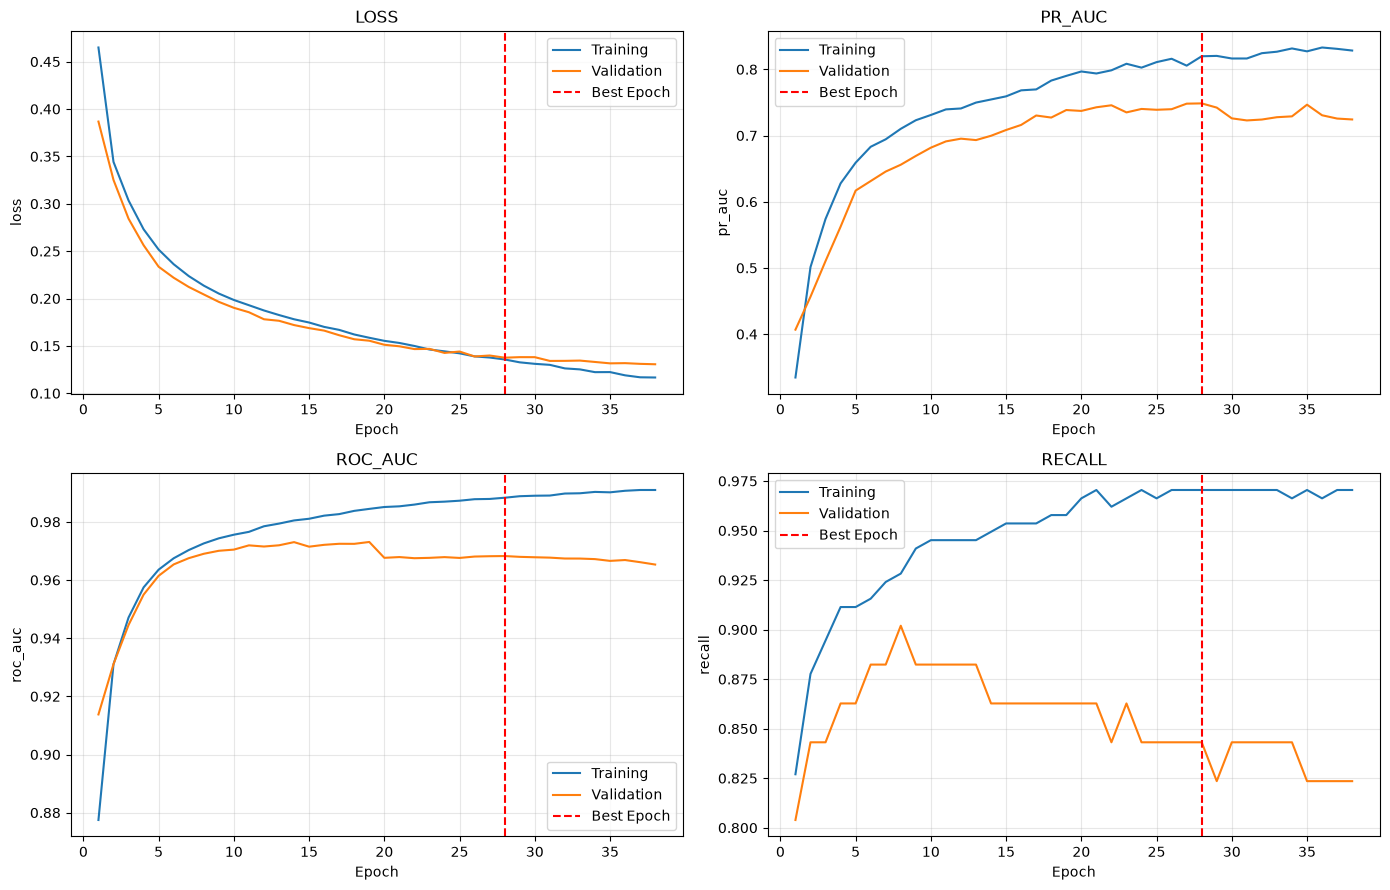

Best epoch: 28


In [55]:
history_df = pd.DataFrame(ann_history.history)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

metrics = ["loss", "pr_auc", "roc_auc", "recall"]
best_epoch = history_df["val_pr_auc"].idxmax() + 1

for ax, metric in zip(axes.flatten(), metrics):
    ax.plot(history_df.index + 1,
            history_df[metric], label="Training")

    ax.plot(history_df.index + 1,
            history_df[f"val_{metric}"], label="Validation")

    ax.axvline(best_epoch, color="red",
               linestyle="--", label="Best Epoch")

    ax.set_title(metric.upper())
    ax.set_xlabel("Epoch")
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Best epoch:", best_epoch)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Baseline ANN,0.950667,0.394495,0.843137,0.5375,0.970568,0.7508


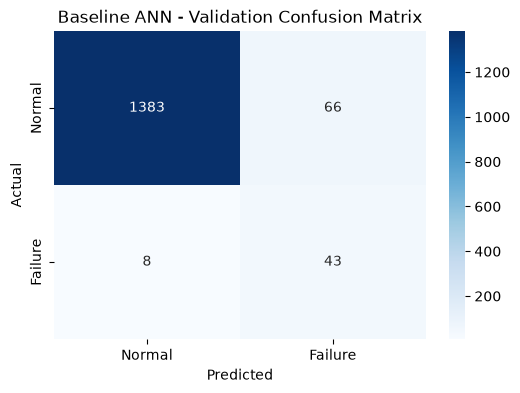

In [56]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

ann_val_prob = ann_model.predict(X_val_proc, verbose=0).ravel()
ann_val_pred = (ann_val_prob >= 0.5).astype(int)

ann_val_metrics = {
    "Accuracy": accuracy_score(y_val, ann_val_pred),
    "Precision": precision_score(y_val, ann_val_pred),
    "Recall": recall_score(y_val, ann_val_pred),
    "F1-Score": f1_score(y_val, ann_val_pred),
    "ROC-AUC": roc_auc_score(y_val, ann_val_prob),
    "PR-AUC": average_precision_score(y_val, ann_val_prob)
}

display(pd.DataFrame([ann_val_metrics], index=["Baseline ANN"]))

plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_matrix(y_val, ann_val_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Failure"],
    yticklabels=["Normal", "Failure"]
)

plt.title("Baseline ANN - Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Controlled Experiment: Impact of Dropout Regularization

Hypothesis:
Dropout regularization improves ANN generalization
and validation Average Precision.

Independent variable: Dropout rate (0.0 vs 0.2).
Dependent variable: Validation Average Precision.

All remaining training configurations and data splits
are held constant. Both configurations are evaluated
using three random seeds to investigate variability.

In [57]:
def build_ann(dropout_rate, seed):

    keras.utils.set_random_seed(seed)

    model = keras.Sequential([
        layers.Input(shape=(X_train_proc.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.AUC(name="roc_auc"),
            keras.metrics.AUC(name="pr_auc", curve="PR")
        ]
    )

    return model

In [58]:
import time

experiment_results = []
experiment_models = {}

seeds = [42, 123, 2026]
dropout_rates = [0.0, 0.2]

for seed in seeds:
    for dropout_rate in dropout_rates:

        print(f"Training: Dropout={dropout_rate}, Seed={seed}")

        model = build_ann(dropout_rate, seed)

        callback = keras.callbacks.EarlyStopping(
            monitor="val_pr_auc",
            mode="max",
            patience=10,
            restore_best_weights=True
        )

        start_time = time.time()

        history = model.fit(
            X_train_proc,
            y_train,
            validation_data=(X_val_proc, y_val),
            epochs=100,
            batch_size=32,
            class_weight=class_weights,
            callbacks=[callback],
            verbose=0
        )

        duration = time.time() - start_time

        prob = model.predict(X_val_proc, verbose=0).ravel()
        pred = (prob >= 0.5).astype(int)

        experiment_results.append({
            "Dropout": dropout_rate,
            "Seed": seed,
            "Epochs": len(history.history["loss"]),
            "Best Epoch": np.argmax(history.history["val_pr_auc"]) + 1,
            "Accuracy": accuracy_score(y_val, pred),
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred),
            "F1-Score": f1_score(y_val, pred),
            "ROC-AUC": roc_auc_score(y_val, prob),
            "PR-AUC": average_precision_score(y_val, prob),
            "Training Time (s)": round(duration, 2)
        })

        experiment_models[(dropout_rate, seed)] = model

        print(f"Completed | PR-AUC: {average_precision_score(y_val, prob):.4f}")

experiment_df = pd.DataFrame(experiment_results)

display(experiment_df)

Training: Dropout=0.0, Seed=42
Completed | PR-AUC: 0.7508
Training: Dropout=0.2, Seed=42
Completed | PR-AUC: 0.7399
Training: Dropout=0.0, Seed=123
Completed | PR-AUC: 0.7299
Training: Dropout=0.2, Seed=123
Completed | PR-AUC: 0.7417
Training: Dropout=0.0, Seed=2026
Completed | PR-AUC: 0.7283
Training: Dropout=0.2, Seed=2026
Completed | PR-AUC: 0.7665


,Dropout,Seed,Epochs,Best Epoch,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Training Time (s)
0,0.0,42,38,28,0.950667,0.394495,0.843137,0.537500,0.970568,0.750800,54.37
1,0.2,42,36,26,0.944000,0.361345,0.843137,0.505882,0.977320,0.739923,48.26
2,0.0,123,30,20,0.951333,0.400000,0.862745,0.546584,0.972462,0.729924,46.00
3,0.2,123,31,21,0.947333,0.387097,0.941176,0.548571,0.975872,0.741689,41.04
4,0.0,2026,37,27,0.950667,0.394495,0.843137,0.537500,0.974249,0.728276,53.37
5,0.2,2026,32,22,0.948000,0.386555,0.901961,0.541176,0.977293,0.766533,48.53


### ANN Architecture and Regularization Optimization

Investigate alternative network architectures, weight
initialization, regularization and class weighting to
improve generalization and rare machine failure detection
under consistent validation conditions.

In [59]:
def build_optimized_ann(
    hidden_units=(64, 32),
    dropout_rate=0.2,
    l1_strength=0.0,
    l2_strength=0.0,
    learning_rate=0.001,
    initializer="glorot_uniform",
    batch_norm=False,
    seed=42
):

    keras.utils.set_random_seed(seed)

    model = keras.Sequential()
    model.add(layers.Input(shape=(X_train_proc.shape[1],)))

    for units in hidden_units:

        model.add(layers.Dense(
            units,
            kernel_initializer=initializer,
            kernel_regularizer=keras.regularizers.L1L2(
                l1=l1_strength,
                l2=l2_strength
            )
        ))

        if batch_norm:
            model.add(layers.BatchNormalization())

        model.add(layers.Activation("relu"))

    model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.AUC(name="roc_auc"),
            keras.metrics.AUC(name="pr_auc", curve="PR")
        ]
    )

    return model

In [60]:
architectures = {
    "Compact ANN": (32, 16),
    "Standard ANN": (64, 32),
    "Deep ANN": (128, 64, 32)
}

architecture_results = []
architecture_models = {}

for name, units in architectures.items():
    for seed in seeds:

        print(f"Training: {name} | Seed: {seed}")

        model = build_optimized_ann(
            hidden_units=units,
            dropout_rate=0.2,
            seed=seed
        )

        callback = keras.callbacks.EarlyStopping(
            monitor="val_pr_auc",
            mode="max",
            patience=10,
            restore_best_weights=True
        )

        history = model.fit(
            X_train_proc,
            y_train,
            validation_data=(X_val_proc, y_val),
            epochs=100,
            batch_size=32,
            class_weight=class_weights,
            callbacks=[callback],
            verbose=0
        )

        prob = model.predict(X_val_proc, verbose=0).ravel()
        pred = (prob >= 0.5).astype(int)

        architecture_results.append({
            "Architecture": name,
            "Seed": seed,
            "Parameters": model.count_params(),
            "Best Epoch": np.argmax(history.history["val_pr_auc"]) + 1,
            "Accuracy": accuracy_score(y_val, pred),
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred),
            "F1-Score": f1_score(y_val, pred),
            "ROC-AUC": roc_auc_score(y_val, prob),
            "PR-AUC": average_precision_score(y_val, prob)
        })

        architecture_models[(name, seed)] = model

        print(f"Completed | PR-AUC: {average_precision_score(y_val, prob):.4f}")

architecture_df = pd.DataFrame(architecture_results)

display(architecture_df.round(4))

Training: Compact ANN | Seed: 42
Completed | PR-AUC: 0.7372
Training: Compact ANN | Seed: 123
Completed | PR-AUC: 0.7709
Training: Compact ANN | Seed: 2026
Completed | PR-AUC: 0.6898
Training: Standard ANN | Seed: 42
Completed | PR-AUC: 0.7399
Training: Standard ANN | Seed: 123
Completed | PR-AUC: 0.7417
Training: Standard ANN | Seed: 2026
Completed | PR-AUC: 0.7665
Training: Deep ANN | Seed: 42
Completed | PR-AUC: 0.7470
Training: Deep ANN | Seed: 123
Completed | PR-AUC: 0.7566
Training: Deep ANN | Seed: 2026
Completed | PR-AUC: 0.7533


,Architecture,Seed,Parameters,Best Epoch,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Compact ANN,42,1057,39,0.9400,0.3465,0.8627,0.4944,0.9740,0.7372
1,Compact ANN,123,1057,57,0.9527,0.4074,0.8627,0.5535,0.9773,0.7709
2,Compact ANN,2026,1057,34,0.9407,0.3492,0.8627,0.4972,0.9763,0.6898
3,Standard ANN,42,3137,26,0.9440,0.3613,0.8431,0.5059,0.9773,0.7399
4,Standard ANN,123,3137,21,0.9473,0.3871,0.9412,0.5486,0.9759,0.7417
5,Standard ANN,2026,3137,22,0.9480,0.3866,0.9020,0.5412,0.9773,0.7665
6,Deep ANN,42,12417,21,0.9520,0.4019,0.8431,0.5443,0.9739,0.7470
7,Deep ANN,123,12417,24,0.9593,0.4444,0.7843,0.5674,0.9713,0.7566
8,Deep ANN,2026,12417,8,0.9387,0.3504,0.9412,0.5106,0.9753,0.7533


### Controlled Experiment: Weight Initialization

Investigate whether He Normal initialization improves
ANN performance compared with Glorot Uniform when
using ReLU activation functions.

All other training configurations remain unchanged.

In [61]:
initialization_results = []
initialization_models = {}

for initializer in ["glorot_uniform", "he_normal"]:
    for seed in seeds:

        print(f"Training: {initializer} | Seed: {seed}")

        model = build_optimized_ann(
            hidden_units=(64, 32),
            dropout_rate=0.2,
            initializer=initializer,
            seed=seed
        )

        callback = keras.callbacks.EarlyStopping(
            monitor="val_pr_auc",
            mode="max",
            patience=10,
            restore_best_weights=True
        )

        history = model.fit(
            X_train_proc,
            y_train,
            validation_data=(X_val_proc, y_val),
            epochs=100,
            batch_size=32,
            class_weight=class_weights,
            callbacks=[callback],
            verbose=0
        )

        prob = model.predict(X_val_proc, verbose=0).ravel()
        pred = (prob >= 0.5).astype(int)

        initialization_results.append({
            "Initializer": initializer,
            "Seed": seed,
            "Accuracy": accuracy_score(y_val, pred),
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred),
            "F1-Score": f1_score(y_val, pred),
            "ROC-AUC": roc_auc_score(y_val, prob),
            "PR-AUC": average_precision_score(y_val, prob)
        })

        initialization_models[(initializer, seed)] = model

        print(f"Completed | PR-AUC: {average_precision_score(y_val, prob):.4f}")

initialization_df = pd.DataFrame(initialization_results)

display(initialization_df.round(4))

Training: glorot_uniform | Seed: 42
Completed | PR-AUC: 0.7399
Training: glorot_uniform | Seed: 123
Completed | PR-AUC: 0.7417
Training: glorot_uniform | Seed: 2026
Completed | PR-AUC: 0.7665
Training: he_normal | Seed: 42
Completed | PR-AUC: 0.7126
Training: he_normal | Seed: 123
Completed | PR-AUC: 0.7638
Training: he_normal | Seed: 2026
Completed | PR-AUC: 0.7299


,Initializer,Seed,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,glorot_uniform,42,0.9440,0.3613,0.8431,0.5059,0.9773,0.7399
1,glorot_uniform,123,0.9473,0.3871,0.9412,0.5486,0.9759,0.7417
2,glorot_uniform,2026,0.9480,0.3866,0.9020,0.5412,0.9773,0.7665
3,he_normal,42,0.9513,0.3962,0.8235,0.5350,0.9697,0.7126
4,he_normal,123,0.9380,0.3409,0.8824,0.4918,0.9708,0.7638
5,he_normal,2026,0.9460,0.3750,0.8824,0.5263,0.9765,0.7299


### Controlled Experiment: L1 and L2 Regularization

Investigate the impact of weight regularization on ANN
generalization and rare machine failure detection.

Compare L1 and L2 penalties while keeping architecture,
weight initialization, dropout and training conditions fixed.

In [62]:
regularization_configs = {
    "L1": (0.0001, 0),
    "Weak L2": (0, 0.0001),
    "Stronger L2": (0, 0.001)
}

regularization_results = []
regularization_models = {}

for name, (l1, l2) in regularization_configs.items():
    for seed in seeds:

        print(f"Training: {name} | Seed: {seed}")

        model = build_optimized_ann(
            hidden_units=(64, 32),
            dropout_rate=0.2,
            initializer="glorot_uniform",
            l1_strength=l1,
            l2_strength=l2,
            seed=seed
        )

        callback = keras.callbacks.EarlyStopping(
            monitor="val_pr_auc",
            mode="max",
            patience=10,
            restore_best_weights=True
        )

        history = model.fit(
            X_train_proc,
            y_train,
            validation_data=(X_val_proc, y_val),
            epochs=100,
            batch_size=32,
            class_weight=class_weights,
            callbacks=[callback],
            verbose=0
        )

        prob = model.predict(X_val_proc, verbose=0).ravel()
        pred = (prob >= 0.5).astype(int)

        regularization_results.append({
            "Regularization": name,
            "L1": l1,
            "L2": l2,
            "Seed": seed,
            "Best Epoch": np.argmax(history.history["val_pr_auc"]) + 1,
            "Accuracy": accuracy_score(y_val, pred),
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred),
            "F1-Score": f1_score(y_val, pred),
            "ROC-AUC": roc_auc_score(y_val, prob),
            "PR-AUC": average_precision_score(y_val, prob)
        })

        regularization_models[(name, seed)] = model

        print(f"Completed | PR-AUC: {average_precision_score(y_val, prob):.4f}")

regularization_df = pd.DataFrame(regularization_results)

display(regularization_df.round(4))

Training: L1 | Seed: 42
Completed | PR-AUC: 0.7611
Training: L1 | Seed: 123
Completed | PR-AUC: 0.7595
Training: L1 | Seed: 2026
Completed | PR-AUC: 0.7798
Training: Weak L2 | Seed: 42
Completed | PR-AUC: 0.7422
Training: Weak L2 | Seed: 123
Completed | PR-AUC: 0.7409
Training: Weak L2 | Seed: 2026
Completed | PR-AUC: 0.7673
Training: Stronger L2 | Seed: 42
Completed | PR-AUC: 0.7552
Training: Stronger L2 | Seed: 123
Completed | PR-AUC: 0.7838
Training: Stronger L2 | Seed: 2026
Completed | PR-AUC: 0.7759


,Regularization,L1,L2,Seed,Best Epoch,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,L1,0.0001,0.0000,42,35,0.9407,0.3516,0.8824,0.5028,0.9780,0.7611
1,L1,0.0001,0.0000,123,34,0.9493,0.3932,0.9020,0.5476,0.9768,0.7595
2,L1,0.0001,0.0000,2026,30,0.9580,0.4423,0.9020,0.5935,0.9791,0.7798
3,Weak L2,0.0000,0.0001,42,38,0.9453,0.3675,0.8431,0.5119,0.9761,0.7422
4,Weak L2,0.0000,0.0001,123,31,0.9433,0.3651,0.9020,0.5198,0.9748,0.7409
5,Weak L2,0.0000,0.0001,2026,22,0.9447,0.3730,0.9216,0.5311,0.9778,0.7673
6,Stronger L2,0.0000,0.0010,42,34,0.9440,0.3680,0.9020,0.5227,0.9777,0.7552
7,Stronger L2,0.0000,0.0010,123,46,0.9507,0.4017,0.9216,0.5595,0.9780,0.7838
8,Stronger L2,0.0000,0.0010,2026,30,0.9473,0.3833,0.9020,0.5380,0.9778,0.7759


### Controlled Experiment: Class Weight Optimization

Investigate the impact of different class weight ratios
on failure detection, false alarms and model performance.

Maintain consistent architecture, regularization,
initialization and training conditions while varying
the relative importance assigned to machine failures.

In [63]:
weight_ratios = [1, 5, 10]

n0 = (y_train == 0).sum()
n1 = (y_train == 1).sum()

weight_results = []
weight_models = {}

for ratio in weight_ratios:

    # Normalize weights to maintain an average weight of 1
    w0 = len(y_train) / (n0 + ratio * n1)
    w1 = ratio * w0

    custom_weights = {0: float(w0), 1: float(w1)}

    for seed in seeds:

        print(f"Training: Weight Ratio={ratio}:1 | Seed={seed}")

        model = build_optimized_ann(
            hidden_units=(64, 32),
            dropout_rate=0.2,
            l2_strength=0.001,
            initializer="glorot_uniform",
            seed=seed
        )

        callback = keras.callbacks.EarlyStopping(
            monitor="val_pr_auc",
            mode="max",
            patience=10,
            restore_best_weights=True
        )

        history = model.fit(
            X_train_proc,
            y_train,
            validation_data=(X_val_proc, y_val),
            epochs=100,
            batch_size=32,
            class_weight=custom_weights,
            callbacks=[callback],
            verbose=0
        )

        prob = model.predict(X_val_proc, verbose=0).ravel()
        pred = (prob >= 0.5).astype(int)

        tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

        weight_results.append({
            "Weight Ratio": ratio,
            "Seed": seed,
            "Accuracy": accuracy_score(y_val, pred),
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred),
            "F1-Score": f1_score(y_val, pred),
            "ROC-AUC": roc_auc_score(y_val, prob),
            "PR-AUC": average_precision_score(y_val, prob),
            "False Positives": fp,
            "False Negatives": fn
        })

        weight_models[(ratio, seed)] = model

        print(f"Completed | PR-AUC: {average_precision_score(y_val, prob):.4f}")

weight_df = pd.DataFrame(weight_results)

display(weight_df.round(4))

Training: Weight Ratio=1:1 | Seed=42
Completed | PR-AUC: 0.7543
Training: Weight Ratio=1:1 | Seed=123
Completed | PR-AUC: 0.7455
Training: Weight Ratio=1:1 | Seed=2026
Completed | PR-AUC: 0.7236
Training: Weight Ratio=5:1 | Seed=42
Completed | PR-AUC: 0.8046
Training: Weight Ratio=5:1 | Seed=123
Completed | PR-AUC: 0.7911
Training: Weight Ratio=5:1 | Seed=2026
Completed | PR-AUC: 0.7709
Training: Weight Ratio=10:1 | Seed=42
Completed | PR-AUC: 0.7919
Training: Weight Ratio=10:1 | Seed=123
Completed | PR-AUC: 0.7878
Training: Weight Ratio=10:1 | Seed=2026
Completed | PR-AUC: 0.7918


,Weight Ratio,Seed,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,False Positives,False Negatives
0,1,42,0.9773,0.7931,0.4510,0.5750,0.9792,0.7543,6,28
1,1,123,0.9793,0.7632,0.5686,0.6517,0.9803,0.7455,9,22
2,1,2026,0.9787,0.8276,0.4706,0.6000,0.9743,0.7236,5,27
3,5,42,0.9760,0.6154,0.7843,0.6897,0.9812,0.8046,25,11
4,5,123,0.9753,0.6061,0.7843,0.6838,0.9803,0.7911,26,11
5,5,2026,0.9747,0.6000,0.7647,0.6724,0.9807,0.7709,26,12
6,10,42,0.9673,0.5125,0.8039,0.6260,0.9802,0.7919,39,10
7,10,123,0.9667,0.5060,0.8235,0.6269,0.9805,0.7878,41,9
8,10,2026,0.9627,0.4713,0.8039,0.5942,0.9817,0.7918,46,10


### Controlled Experiment: Learning Rate Optimization

Investigate whether a smaller learning rate improves
ANN convergence and generalization while maintaining
the selected architecture, regularization and class weights.

In [64]:
lr_results = []
lr_models = {}

ratio = 10

w0 = len(y_train) / (n0 + ratio * n1)
optimized_weights = {0: float(w0), 1: float(ratio * w0)}

for seed in seeds:

    print(f"Training: Learning Rate=0.0005 | Seed={seed}")

    model = build_optimized_ann(
        hidden_units=(64, 32),
        dropout_rate=0.2,
        l2_strength=0.001,
        initializer="glorot_uniform",
        learning_rate=0.0005,
        seed=seed
    )

    callback = keras.callbacks.EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_proc,
        y_train,
        validation_data=(X_val_proc, y_val),
        epochs=100,
        batch_size=32,
        class_weight=optimized_weights,
        callbacks=[callback],
        verbose=0
    )

    prob = model.predict(X_val_proc, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)

    lr_results.append({
        "Learning Rate": 0.0005,
        "Seed": seed,
        "Best Epoch": np.argmax(history.history["val_pr_auc"]) + 1,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred),
        "F1-Score": f1_score(y_val, pred),
        "ROC-AUC": roc_auc_score(y_val, prob),
        "PR-AUC": average_precision_score(y_val, prob)
    })

    lr_models[seed] = model

    print(f"Completed | PR-AUC: {average_precision_score(y_val, prob):.4f}")

lr_df = pd.DataFrame(lr_results)

display(lr_df.round(4))

Training: Learning Rate=0.0005 | Seed=42
Completed | PR-AUC: 0.7791
Training: Learning Rate=0.0005 | Seed=123
Completed | PR-AUC: 0.7645
Training: Learning Rate=0.0005 | Seed=2026
Completed | PR-AUC: 0.7889


,Learning Rate,Seed,Best Epoch,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,0.0005,42,67,0.9673,0.5125,0.8039,0.6260,0.9804,0.7791
1,0.0005,123,45,0.9607,0.4565,0.8235,0.5874,0.9787,0.7645
2,0.0005,2026,63,0.9667,0.5062,0.8039,0.6212,0.9805,0.7889


In [65]:
INSPECTION_COST = 500
MISSED_FAILURE_COST = 10000

final_ann = weight_models[(10, 42)]

# Collect validation and test prediction functions
candidates = {}

for name, model in models.items():
    candidates[name] = (
        model.predict_proba(X_val_proc)[:, 1],
        lambda m=model: m.predict_proba(X_test_proc)[:, 1]
    )

for name, model in tuned_models.items():
    candidates[f"{name} (Tuned)"] = (
        model.predict_proba(X_val_clean)[:, 1],
        lambda m=model: m.predict_proba(X_test_clean)[:, 1]
    )

for name, model in {
    "Baseline ANN": ann_model,
    "Optimized ANN (5:1)": weight_models[(5, 42)],
    "Optimized ANN (10:1)": final_ann
}.items():
    candidates[name] = (
        model.predict(X_val_proc, verbose=0).ravel(),
        lambda m=model: m.predict(X_test_proc, verbose=0).ravel()
    )


def evaluate_model(y, prob, threshold):

    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()

    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred),
        "F1-Score": f1_score(y, pred),
        "ROC-AUC": roc_auc_score(y, prob),
        "PR-AUC": average_precision_score(y, prob),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Business Cost": (tp + fp) * INSPECTION_COST
                         + fn * MISSED_FAILURE_COST
    }


validation_results = []

for name, (prob, _) in candidates.items():

    thresholds = np.r_[np.unique(prob), np.inf]
    actual = np.asarray(y_val)

    costs = []

    for threshold in thresholds:
        pred = prob >= threshold

        cost = (
            pred.sum() * INSPECTION_COST
            + ((actual == 1) & ~pred).sum() * MISSED_FAILURE_COST
        )

        costs.append(cost)

    best_threshold = thresholds[np.argmin(costs)]

    validation_results.append({
        "Model": name,
        **evaluate_model(y_val, prob, best_threshold)
    })

validation_comparison = pd.DataFrame(validation_results)
validation_comparison = validation_comparison.sort_values(
    ["Business Cost", "PR-AUC"],
    ascending=[True, False]
)

selected_model = validation_comparison.iloc[0]["Model"]

display(validation_comparison.round(4))
print("Selected model:", selected_model)

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,TN,FP,FN,TP,Business Cost
6,Optimized ANN (5:1),0.1319,0.9467,0.3876,0.9804,0.5556,0.9812,0.8046,1370,79,1,50,74500
2,Gradient Boosting (Default),0.0086,0.9447,0.3788,0.9804,0.5464,0.9849,0.9278,1367,82,1,50,76000
4,LightGBM (Weighted),0.3623,0.9793,0.6351,0.9216,0.7520,0.9843,0.8908,1422,27,4,47,77000
1,Random Forest (Balanced),0.0600,0.9533,0.4188,0.9608,0.5833,0.9820,0.8806,1381,68,2,49,78500
7,Optimized ANN (10:1),0.1724,0.9387,0.3546,0.9804,0.5208,0.9802,0.7919,1358,91,1,50,80500
3,XGBoost (Weighted),0.1468,0.9420,0.3657,0.9608,0.5297,0.9841,0.8589,1364,85,2,49,87000
5,Baseline ANN,0.2257,0.9160,0.2807,0.9412,0.4324,0.9706,0.7508,1326,123,3,48,115500
0,Logistic Regression (Balanced),0.4575,0.8633,0.1765,0.8235,0.2907,0.9134,0.3906,1253,196,9,42,209000


Selected model: Optimized ANN (5:1)


In [67]:
test_results = []

for _, row in validation_comparison.iterrows():

    name = row["Model"]
    threshold = row["Threshold"]

    test_prob = candidates[name][1]()

    test_results.append({
        "Model": name,
        **evaluate_model(y_test, test_prob, threshold)
    })

final_comparison = pd.DataFrame(test_results)

display(final_comparison.round(4))

print("Validation-selected champion:", selected_model)

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,TN,FP,FN,TP,Business Cost
0,Optimized ANN (5:1),0.1319,0.9367,0.3382,0.9020,0.4920,0.9856,0.8070,1359,90,5,46,118000
1,Gradient Boosting (Default),0.0086,0.9347,0.3333,0.9216,0.4896,0.9587,0.8917,1355,94,4,47,110500
2,LightGBM (Weighted),0.3623,0.9720,0.5570,0.8627,0.6769,0.9847,0.8802,1414,35,7,44,109500
3,Random Forest (Balanced),0.0600,0.9453,0.3740,0.9020,0.5287,0.9703,0.9084,1372,77,5,46,111500
4,Optimized ANN (10:1),0.1724,0.9233,0.2975,0.9216,0.4498,0.9832,0.7748,1338,111,4,47,119000
5,XGBoost (Weighted),0.1468,0.9327,0.3239,0.9020,0.4767,0.9860,0.8771,1353,96,5,46,121000
6,Baseline ANN,0.2257,0.9060,0.2581,0.9412,0.4051,0.9773,0.7431,1311,138,3,48,123000
7,Logistic Regression (Balanced),0.4575,0.8540,0.1719,0.8627,0.2866,0.9452,0.4696,1237,212,7,44,198000


Validation-selected champion: Optimized ANN (5:1)


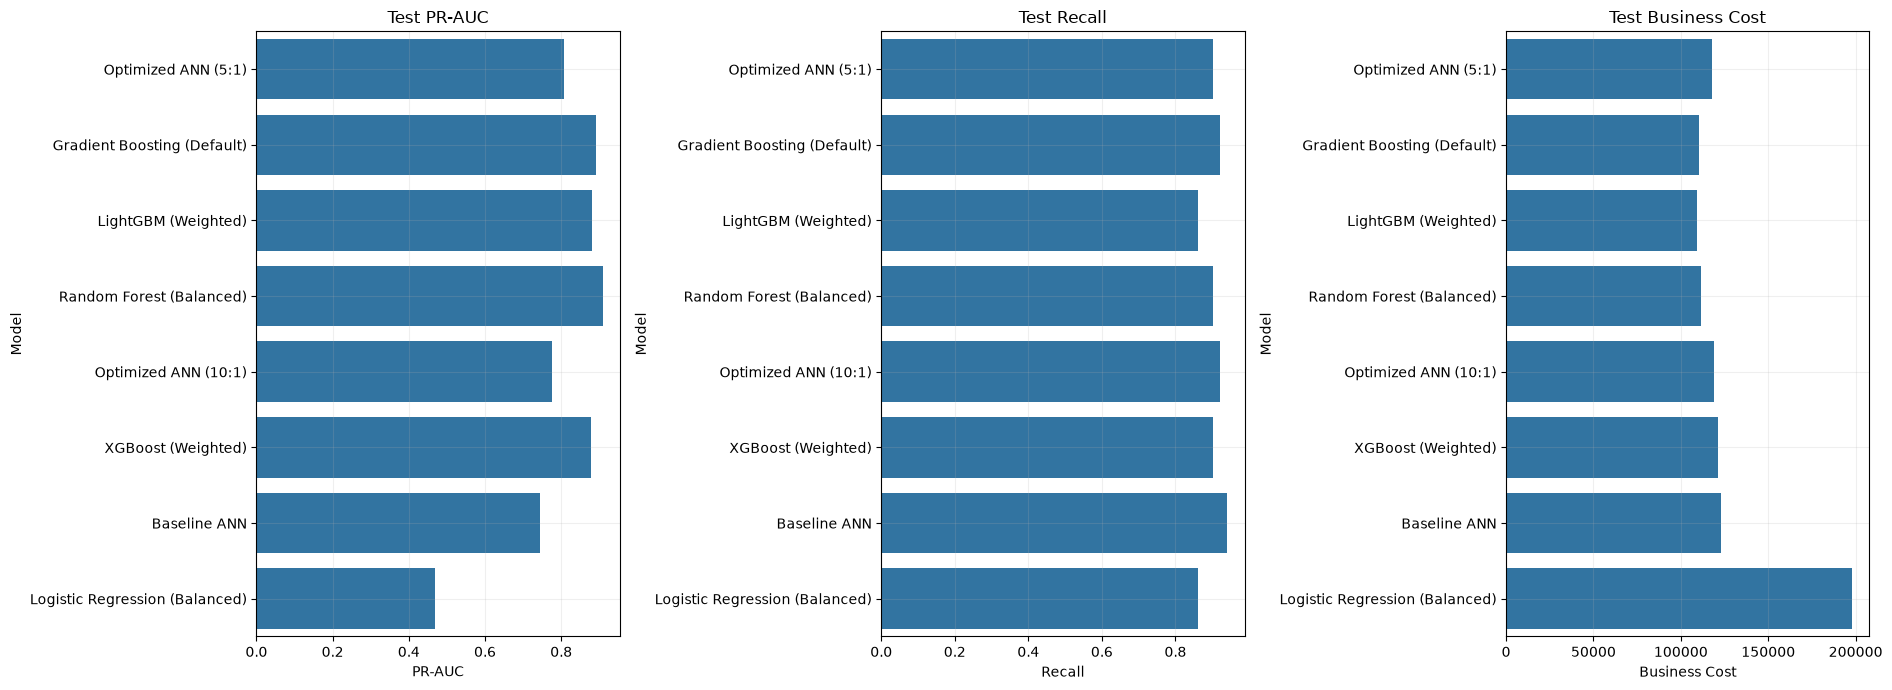

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(19, 7))

for ax, metric in zip(
    axes, ["PR-AUC", "Recall", "Business Cost"]
):
    sns.barplot(
        data=final_comparison,
        y="Model",
        x=metric,
        ax=ax
    )

    ax.set_title(f"Test {metric}")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [69]:
os.makedirs("../results", exist_ok=True)

all_experiments = pd.concat([
    experiment_df.assign(Experiment="Dropout"),
    architecture_df.assign(Experiment="Architecture"),
    initialization_df.assign(Experiment="Initialization"),
    regularization_df.assign(Experiment="Regularization"),
    weight_df.assign(Experiment="Class Weight"),
    lr_df.assign(Experiment="Learning Rate")
], ignore_index=True)

all_experiments.to_csv(
    "../results/experiment_results.csv", index=False
)

final_comparison.to_csv(
    "../results/model_comparison.csv", index=False
)

validation_comparison.to_csv(
    "../results/validation_comparison.csv", index=False
)

final_ann.save("../models/optimized_ann.keras")

joblib.dump(
    preprocessor,
    "../models/ann_preprocessor.joblib"
)

print("Results and ANN artifacts saved successfully.")

Results and ANN artifacts saved successfully.


In [70]:
print("Available tuned models:", list(tuned_models.keys()))

best_ann = weight_models[(5, 42)]
best_ann.save("../models/optimized_ann_5to1.keras")

print("Best validation-selected ANN saved successfully.")

Available tuned models: []
Best validation-selected ANN saved successfully.


In [71]:
artifact = joblib.load(
    "../models/gradient_boosting_champion.joblib"
)

tuned_models["Gradient Boosting"] = artifact["model"]

X_val_clean = sanitize_cols(X_val)
X_test_clean = sanitize_cols(X_test)

print("Recovered tuned models:", list(tuned_models.keys()))

print("Validation PR-AUC:", average_precision_score(
    y_val,
    tuned_models["Gradient Boosting"].predict_proba(X_val_clean)[:, 1]
))

Recovered tuned models: ['Gradient Boosting']
Validation PR-AUC: 0.920625137427181


,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,TN,FP,FN,TP,Business Cost
0,0.0660,0.9160,0.2857,0.9804,0.4425,0.9812,0.8046,1324,125,1,50,97500
1,0.0989,0.9353,0.3425,0.9804,0.5076,0.9812,0.8046,1353,96,1,50,83000
2,0.1319,0.9467,0.3876,0.9804,0.5556,0.9812,0.8046,1370,79,1,50,74500
3,0.1649,0.9513,0.4068,0.9412,0.5680,0.9812,0.8046,1379,70,3,48,89000
4,0.1979,0.9560,0.4299,0.9020,0.5823,0.9812,0.8046,1388,61,5,46,103500
5,0.5000,0.9760,0.6154,0.7843,0.6897,0.9812,0.8046,1424,25,11,40,142500


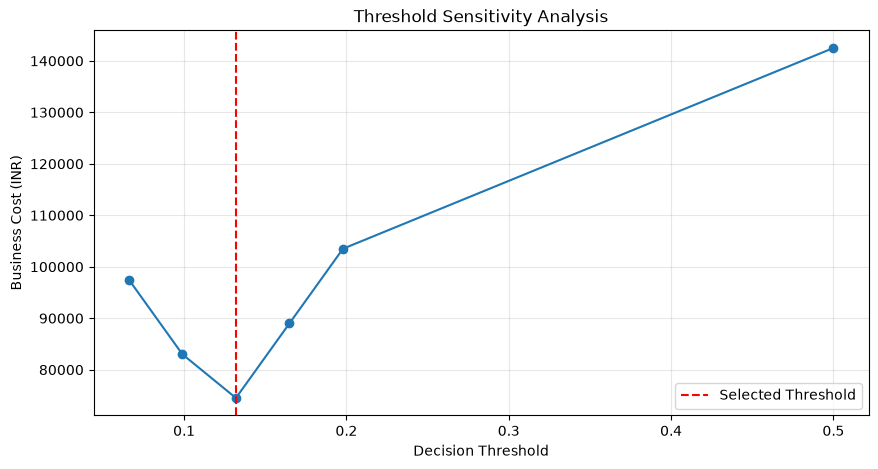

In [72]:
selected_row = validation_comparison.iloc[0]

selected_model = selected_row["Model"]
selected_threshold = selected_row["Threshold"]

val_prob = candidates[selected_model][0]

thresholds = np.unique(np.clip([
    selected_threshold * 0.5,
    selected_threshold * 0.75,
    selected_threshold,
    selected_threshold * 1.25,
    selected_threshold * 1.5,
    0.5
], 0, 1))

sensitivity_df = pd.DataFrame([
    evaluate_model(y_val, val_prob, t)
    for t in thresholds
])

display(sensitivity_df.round(4))

plt.figure(figsize=(10, 5))
plt.plot(
    sensitivity_df["Threshold"],
    sensitivity_df["Business Cost"],
    marker="o"
)

plt.axvline(
    selected_threshold,
    color="red",
    linestyle="--",
    label="Selected Threshold"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Business Cost (INR)")
plt.title("Threshold Sensitivity Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [73]:
test_prob = candidates[selected_model][1]()

risk_df = pd.DataFrame({
    "Record_ID": X_test.index,
    "Failure_Risk_Score": test_prob
})

risk_df["Risk_Level"] = np.select(
    [
        test_prob >= selected_threshold,
        test_prob >= selected_threshold * 0.5
    ],
    ["High", "Medium"],
    default="Low"
)

risk_df["Recommended_Action"] = risk_df["Risk_Level"].map({
    "High": "Prioritize inspection",
    "Medium": "Increase monitoring",
    "Low": "Routine maintenance"
})

risk_df = risk_df.sort_values(
    "Failure_Risk_Score", ascending=False
)

display(risk_df.head(10))
display(risk_df["Risk_Level"].value_counts())

sensitivity_df.to_csv(
    "../results/threshold_sensitivity.csv", index=False
)

risk_df.to_csv(
    "../results/maintenance_priority.csv", index=False
)

print("Selected model:", selected_model)
print("Decision threshold:", selected_threshold)

,Record_ID,Failure_Risk_Score,Risk_Level,Recommended_Action
1178,8307,0.999982,High,Prioritize inspection
720,8582,0.999895,High,Prioritize inspection
393,7083,0.999877,High,Prioritize inspection
456,4565,0.999690,High,Prioritize inspection
636,4729,0.999675,High,Prioritize inspection
961,4570,0.999598,High,Prioritize inspection
35,1391,0.999475,High,Prioritize inspection
1149,8437,0.999225,High,Prioritize inspection
494,7997,0.998574,High,Prioritize inspection
159,9664,0.998205,High,Prioritize inspection


Risk_Level
Low       1313
High       136
Medium      51
Name: count, dtype: int64

Selected model: Optimized ANN (5:1)
Decision threshold: 0.1319321244955063


In [74]:
import importlib
import src.predict as prediction_module

importlib.reload(prediction_module)

artifact = joblib.load("../models/gradient_boosting_champion.joblib")
gb = artifact["model"]

X_val_clean = sanitize_cols(X_val)
X_test_clean = sanitize_cols(X_test)

# Restore tuned Gradient Boosting
name = "Gradient Boosting (Tuned)"

candidates[name] = (
    gb.predict_proba(X_val_clean)[:, 1],
    lambda: gb.predict_proba(X_test_clean)[:, 1]
)

# Optimize threshold using validation data only
prob = candidates[name][0]
thresholds = np.r_[np.unique(prob), np.inf]

costs = [
    evaluate_model(y_val, prob, t)["Business Cost"]
    for t in thresholds
]

best_threshold = thresholds[np.argmin(costs)]

validation_comparison = pd.concat([
    validation_comparison[
        validation_comparison["Model"] != name
    ],
    pd.DataFrame([{
        "Model": name,
        **evaluate_model(y_val, prob, best_threshold)
    }])
], ignore_index=True).sort_values(
    ["Business Cost", "PR-AUC"],
    ascending=[True, False]
)

selected_model = validation_comparison.iloc[0]["Model"]
selected_threshold = float(
    validation_comparison.iloc[0]["Threshold"]
)

# Final test evaluation
final_comparison = pd.DataFrame([
    {
        "Model": row["Model"],
        **evaluate_model(
            y_test,
            candidates[row["Model"]][1](),
            row["Threshold"]
        )
    }
    for _, row in validation_comparison.iterrows()
])

validation_comparison.to_csv(
    "../results/validation_comparison.csv", index=False
)

final_comparison.to_csv(
    "../results/model_comparison.csv", index=False
)

# Verify inference consistency
raw = df.loc[X_test.index, [
    "Type", "Air temperature [K]",
    "Process temperature [K]", "Rotational speed [rpm]",
    "Torque [Nm]", "Tool wear [min]"
]]

rebuilt = prediction_module.engineer_features(raw)
rebuilt = rebuilt[X_test_clean.columns]

pd.testing.assert_frame_equal(
    rebuilt, X_test_clean, check_dtype=False,
    check_exact=False, rtol=1e-10, atol=1e-10
)

np.testing.assert_allclose(
    gb.predict_proba(rebuilt),
    gb.predict_proba(X_test_clean)
)

print("Inference verification passed.")
print("Selected model:", selected_model)
print("Decision threshold:", selected_threshold)

display(validation_comparison.round(4))
display(final_comparison.round(4))

Inference verification passed.
Selected model: Gradient Boosting (Tuned)
Decision threshold: 0.011186758056712235


,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,TN,FP,FN,TP,Business Cost
8,Gradient Boosting (Tuned),0.0112,0.9473,0.3906,0.9804,0.5587,0.9818,0.9206,1371,78,1,50,74000
0,Optimized ANN (5:1),0.1319,0.9467,0.3876,0.9804,0.5556,0.9812,0.8046,1370,79,1,50,74500
1,Gradient Boosting (Default),0.0086,0.9447,0.3788,0.9804,0.5464,0.9849,0.9278,1367,82,1,50,76000
2,LightGBM (Weighted),0.3623,0.9793,0.6351,0.9216,0.7520,0.9843,0.8908,1422,27,4,47,77000
3,Random Forest (Balanced),0.0600,0.9533,0.4188,0.9608,0.5833,0.9820,0.8806,1381,68,2,49,78500
4,Optimized ANN (10:1),0.1724,0.9387,0.3546,0.9804,0.5208,0.9802,0.7919,1358,91,1,50,80500
5,XGBoost (Weighted),0.1468,0.9420,0.3657,0.9608,0.5297,0.9841,0.8589,1364,85,2,49,87000
6,Baseline ANN,0.2257,0.9160,0.2807,0.9412,0.4324,0.9706,0.7508,1326,123,3,48,115500
7,Logistic Regression (Balanced),0.4575,0.8633,0.1765,0.8235,0.2907,0.9134,0.3906,1253,196,9,42,209000


,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,TN,FP,FN,TP,Business Cost
0,Gradient Boosting (Tuned),0.0112,0.9380,0.3500,0.9608,0.5131,0.9751,0.9214,1358,91,2,49,90000
1,Optimized ANN (5:1),0.1319,0.9367,0.3382,0.9020,0.4920,0.9856,0.8070,1359,90,5,46,118000
2,Gradient Boosting (Default),0.0086,0.9347,0.3333,0.9216,0.4896,0.9587,0.8917,1355,94,4,47,110500
3,LightGBM (Weighted),0.3623,0.9720,0.5570,0.8627,0.6769,0.9847,0.8802,1414,35,7,44,109500
4,Random Forest (Balanced),0.0600,0.9453,0.3740,0.9020,0.5287,0.9703,0.9084,1372,77,5,46,111500
5,Optimized ANN (10:1),0.1724,0.9233,0.2975,0.9216,0.4498,0.9832,0.7748,1338,111,4,47,119000
6,XGBoost (Weighted),0.1468,0.9327,0.3239,0.9020,0.4767,0.9860,0.8771,1353,96,5,46,121000
7,Baseline ANN,0.2257,0.9060,0.2581,0.9412,0.4051,0.9773,0.7431,1311,138,3,48,123000
8,Logistic Regression (Balanced),0.4575,0.8540,0.1719,0.8627,0.2866,0.9452,0.4696,1237,212,7,44,198000


In [75]:
from pathlib import Path
import json

artifact = joblib.load("../models/gradient_boosting_champion.joblib")
gb = artifact["model"]

X_val_clean = sanitize_cols(X_val)
X_test_clean = sanitize_cols(X_test)

candidates["Gradient Boosting (Tuned)"] = (
    gb.predict_proba(X_val_clean)[:, 1],
    lambda: gb.predict_proba(X_test_clean)[:, 1]
)

validation_results = []

for name, (prob, _) in candidates.items():
    thresholds = np.r_[np.unique(prob), np.inf]

    costs = [
        (prob >= t).sum() * INSPECTION_COST
        + ((np.asarray(y_val) == 1) & (prob < t)).sum()
        * MISSED_FAILURE_COST
        for t in thresholds
    ]

    threshold = thresholds[np.argmin(costs)]

    validation_results.append({
        "Model": name,
        **evaluate_model(y_val, prob, threshold)
    })

validation_comparison = pd.DataFrame(
    validation_results
).sort_values(
    ["Business Cost", "PR-AUC"],
    ascending=[True, False]
)

selected_model = validation_comparison.iloc[0]["Model"]
selected_threshold = float(
    validation_comparison.iloc[0]["Threshold"]
)

final_comparison = pd.DataFrame([
    {
        "Model": row["Model"],
        **evaluate_model(
            y_test,
            candidates[row["Model"]][1](),
            row["Threshold"]
        )
    }
    for _, row in validation_comparison.iterrows()
])

validation_comparison.to_csv(
    "../results/validation_comparison.csv", index=False
)

final_comparison.to_csv(
    "../results/model_comparison.csv", index=False
)

weight_models[(5, 42)].save("../models/optimized_ann_5to1.keras")

print("Final model:", selected_model)
print("Threshold:", selected_threshold)
display(final_comparison.round(4))

Final model: Gradient Boosting (Tuned)
Threshold: 0.011186758056712235


,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,TN,FP,FN,TP,Business Cost
0,Gradient Boosting (Tuned),0.0112,0.9380,0.3500,0.9608,0.5131,0.9751,0.9214,1358,91,2,49,90000
1,Optimized ANN (5:1),0.1319,0.9367,0.3382,0.9020,0.4920,0.9856,0.8070,1359,90,5,46,118000
2,Gradient Boosting (Default),0.0086,0.9347,0.3333,0.9216,0.4896,0.9587,0.8917,1355,94,4,47,110500
3,LightGBM (Weighted),0.3623,0.9720,0.5570,0.8627,0.6769,0.9847,0.8802,1414,35,7,44,109500
4,Random Forest (Balanced),0.0600,0.9453,0.3740,0.9020,0.5287,0.9703,0.9084,1372,77,5,46,111500
5,Optimized ANN (10:1),0.1724,0.9233,0.2975,0.9216,0.4498,0.9832,0.7748,1338,111,4,47,119000
6,XGBoost (Weighted),0.1468,0.9327,0.3239,0.9020,0.4767,0.9860,0.8771,1353,96,5,46,121000
7,Baseline ANN,0.2257,0.9060,0.2581,0.9412,0.4051,0.9773,0.7431,1311,138,3,48,123000
8,Logistic Regression (Balanced),0.4575,0.8540,0.1719,0.8627,0.2866,0.9452,0.4696,1237,212,7,44,198000


In [76]:
from matplotlib.backends.backend_pdf import PdfPages
from textwrap import fill

winner = validation_comparison.iloc[0]

test = final_comparison.loc[
    final_comparison["Model"] == selected_model
].iloc[0]

lowest_cost = final_comparison.loc[
    final_comparison["Business Cost"].idxmin()
]

highest_ap = final_comparison.loc[
    final_comparison["PR-AUC"].idxmax()
]

sections = {
    "Business Understanding and Methodology": """
The objective is to identify machine failure risks and reduce
unnecessary maintenance inspections.

Dataset: UCI AI4I 2020 Predictive Maintenance.
10,000 records, 339 failures, 3.39% failure rate.
No missing values or duplicate records were identified.

Seven domain-based features were engineered from six original
predictors. Identifiers and failure-mode indicators were excluded
to prevent target leakage.

Stratified training, validation and test splits of 70:15:15
were used with preprocessing fitted on training data.
""",

    "ANN Development and Research": f"""
A baseline ANN and multiple traditional ML models were developed.

ANN experiments investigated dropout, architecture, initialization,
L1/L2 regularization, class weighting and learning rate.

Total recorded experimental runs: {len(all_experiments)}.

The optimized architecture uses 64 and 32 hidden neurons,
ReLU, Glorot initialization, 20% dropout, L2 regularization
of 0.001 and Adam with a learning rate of 0.001.

Mean validation Average Precision improved from approximately
0.7363 to 0.7905 under the selected optimization sequence.

The experiments do not establish consistent ANN superiority.
""",

    "Business Recommendations": f"""
Validation-selected model: {selected_model}
Decision threshold: {selected_threshold:.6f}

Validation cost: INR {winner['Business Cost']:,.0f}
Test cost: INR {test['Business Cost']:,.0f}
Test recall: {test['Recall']:.2%}
Test Average Precision: {test['PR-AUC']:.4f}

Lowest observed test cost: {lowest_cost['Model']}
Highest observed test Average Precision: {highest_ap['Model']}

Hypothetical costs:
Inspection = INR 500.
Missed failure = INR 10,000.

High-risk records should receive prioritized inspection.
Medium-risk records require additional monitoring.
Low-risk records continue routine maintenance.

Limitations include synthetic data, rare failures, repeated
validation-set reuse, previously inspected test results,
uncalibrated risk scores and hypothetical operational costs.

Real-world deployment requires further prospective validation.
"""
}

report_path = Path("../reports/Final_Technical_Report.pdf")

with PdfPages(report_path) as pdf:

    for title, content in sections.items():

        fig = plt.figure(figsize=(8.27, 11.69))

        fig.text(
            0.08, 0.94,
            "Intelligent Predictive Maintenance",
            fontsize=18, weight="bold"
        )

        fig.text(
            0.08, 0.91,
            "Harshith Katta | Applied AI/ML Assessment",
            fontsize=10
        )

        fig.text(0.08, 0.85, title, fontsize=15, weight="bold")

        body = "\n\n".join(
            fill(p, width=85)
            for p in content.strip().split("\n\n")
        )

        fig.text(
            0.08, 0.80, body,
            fontsize=11, va="top", linespacing=1.6
        )

        pdf.savefig(fig)
        plt.close(fig)

    for metric in ["PR-AUC", "Recall", "Business Cost"]:

        fig, ax = plt.subplots(figsize=(11, 7))

        sns.barplot(
            data=final_comparison,
            y="Model", x=metric, ax=ax
        )

        ax.set_title(f"Final Test Comparison - {metric}")
        plt.tight_layout()
        pdf.savefig(fig)
        plt.close(fig)

readme = "# Intelligent Predictive Maintenance\n\n"
readme += "Author: Harshith Katta\n\n"

for title, content in sections.items():
    readme += f"## {title}\n\n{content.strip()}\n\n"

readme += """
## Dataset
https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

## Execution
1. Install dependencies using pip install -r requirements.txt.
2. Place the dataset in data/ai4i2020.csv.
3. Open notebooks/Predictive_Maintenance.ipynb.
4. Retain the saved Gradient Boosting pipeline for artifact recovery.

## Final Test Results
"""

readme += "\n```\n"
readme += final_comparison.round(4).to_string(index=False)
readme += "\n```\n"

Path("../README.md").write_text(readme, encoding="utf-8")

print("Technical report generated.")
print("README updated successfully.")

Technical report generated.
README updated successfully.
